In [1]:
%env OPENBLAS_NUM_THREADS=1
%env MKL_NUM_THREADS=1
%env NUMEXPR_NUM_THREADS=1

import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"
os.environ["BLIS_NUM_THREADS"] = "1"
os.environ["OMP_DYNAMIC"] = "FALSE"


env: OPENBLAS_NUM_THREADS=1
env: MKL_NUM_THREADS=1
env: NUMEXPR_NUM_THREADS=1


In [2]:
from utils import load_counties, set_plot_style, make_stars, NRI_HAZARD_NAMES

import pandas as pd
import numpy as np
import geopandas as gpd

import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, het_white

import patsy

from statsmodels.iolib.summary2 import summary_col

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import TwoSlopeNorm
import matplotlib as mpl

import pickle

import scipy

import random
np.random.seed(42)
random.seed(42)


In [3]:
set_plot_style()

In [4]:
nri_county = pd.read_parquet("../data_loaded/nri_counties.parquet")

In [5]:
counties = load_counties()

## Modelling counties' PageRanks

County-level counterpart to `3_modelling_pr_cbsa.ipynb`. Builds the Model 1-5 OLS table from the same per-county source files, used as-is rather than population-weighted up to CBSA level, since the county already is the unit of analysis. Only `pagerank_logdiff` is modelled here.

Four of the CBSA notebook's robustness sections are carried over: the Shapley R2 decomposition and Model 5 coefficient plot, the spatial and network dependence diagnostics (Moran's I, Conley spatial-HAC SEs), the capacity-purged composite hazard measures, and the per-hazard OLS check. The temporal windows, sample-period robustness, alternative outcome measures and seniority/industry splits are not reproduced at county level.

### County Aggregated: One Big Beautiful Network

In [6]:
hits_irs=pd.read_parquet("../data_generated/network_metrics/hits_irs_1122.parquet")
hits_exp=pd.read_parquet("../data_generated/network_metrics/hits_exp_1122.parquet")

hits_merged=hits_irs.merge(hits_exp, on=['STCOFIPS'], how='inner', suffixes=('_irs', '_exp'))


In [7]:
hits_merged['pagerank_diff']=hits_merged['pagerank_exp']-hits_merged['pagerank_irs']

hits_merged = hits_merged.merge(counties[['STCOFIPS', 'name', 'ALAND', 'AWATER']], on='STCOFIPS', how='left')
hits_merged['water_perc'] = hits_merged['AWATER'] / (hits_merged['ALAND'] + hits_merged['AWATER']) * 100

hazards = [
    'RISK_SCORE', 'AVLN_RISKS', 'CFLD_RISKS', 'CWAV_RISKS', 'DRGT_RISKS',
    'ERQK_RISKS', 'HAIL_RISKS', 'HWAV_RISKS', 'HRCN_RISKS', 'ISTM_RISKS',
    'LNDS_RISKS', 'LTNG_RISKS', 'RFLD_RISKS', 'SWND_RISKS', 'TRND_RISKS',
    'TSUN_RISKS', 'VLCN_RISKS', 'WFIR_RISKS', 'WNTW_RISKS'
]

nri_county[hazards] = (
    nri_county[hazards]
    .replace(-9999, np.nan)
    .apply(pd.to_numeric, errors='coerce')
)
nri_county['POPULATION'] = pd.to_numeric(nri_county['POPULATION'], errors='coerce')

hits_merged = hits_merged.merge(
    nri_county[['STCOFIPS', 'POPULATION'] + hazards], on='STCOFIPS', how='left'
)

hits_merged['pop_density'] = hits_merged['POPULATION'] / hits_merged['ALAND'] * 1_000_000


In [8]:
## Job postings

jobposts_naics=pd.read_csv('../data_loaded/jobpostings_aggregated/job_postings_county_month_naics.csv')

jobposts_naics['year'] = jobposts_naics['month_year'].str[:4].astype(int)
jobposts_naics = jobposts_naics[jobposts_naics['year'].isin([2016, 2017, 2018, 2019])].reset_index(drop=True)
jobposts_naics['STCOFIPS'] = jobposts_naics['STCOFIPS'].astype(str).str.zfill(5)

total_posts = (
    jobposts_naics
    .groupby("STCOFIPS")
    .n_postings
    .sum()
    .reset_index()
    .rename(columns={"n_postings": "total_postings"})
)

target_posts = (
    jobposts_naics[jobposts_naics["NAICS_2"].isin([51, 52, 53, 54, 55, 56])]
    .groupby("STCOFIPS")
    .n_postings
    .sum()
    .reset_index()
    .rename(columns={"n_postings": "target_postings"})
)

jobposts_share = (
    total_posts
    .merge(target_posts, on="STCOFIPS", how="left")
)

jobposts_share["target_postings"] = jobposts_share["target_postings"].fillna(0)
jobposts_share["share_target_pct"] = (
    100 * jobposts_share["target_postings"] / jobposts_share["total_postings"]
)

hits_merged['STCOFIPS'] = hits_merged['STCOFIPS'].astype(str).str.zfill(5)
hits_merged = hits_merged.merge(jobposts_share, on='STCOFIPS', how='left')
hits_merged['target_postings'] = hits_merged['target_postings'].fillna(0)
hits_merged['n_postings_100k'] = hits_merged['target_postings']/hits_merged['POPULATION']*100_000


In [9]:
business = pd.read_csv("../data_loaded/cbp22co.zip", sep=',')

business["STCOFIPS"] = (
            business["fipstate"].astype(str).str.zfill(2)
            + business["fipscty"].astype(str).str.zfill(3))

business=business[business['naics'].isin(['51----','52----','53----','54----','55----','56----'])]

business=business.groupby('STCOFIPS').agg({'emp':'sum', 'est':'sum'}).reset_index()

hits_merged=hits_merged.merge(business, on='STCOFIPS', how='left')

hits_merged['emp_100k'] = hits_merged['emp']/hits_merged['POPULATION']*100_000
hits_merged['est_100k'] = hits_merged['est']/hits_merged['POPULATION']*100_000


In [10]:
# MY URBAN -- already at county resolution, so used directly (no population-weighting
# up to CBSA, unlike the CBSA notebook). urban_afford.parquet has a handful of exact
# duplicate STCOFIPS rows (73 of 3276) -- drop_duplicates before merging to avoid
# silently inflating the county row count.

urban=pd.read_parquet('../data_loaded/data_final/urban_afford.parquet')
urban['STCOFIPS'] = urban['STCOFIPS'].astype(str).str.zfill(5)
urban = urban.drop_duplicates(subset='STCOFIPS')

hits_merged = hits_merged.merge(
    urban[['STCOFIPS','nat_amenity_score','urbanism','real_estate_taxes_med',
           'med_home_price2017','income_price_ratio2023','inequality_ratio']],
    on='STCOFIPS', how='left'
)

urbanism_dict = {
    "6 - Noncore": 1,
    "5 - Micropolitan": 2,
    "4 - Small metro": 3,
    "3 - Medium metro": 4,
    "2 - Large fringe metro": 5,
    "1 - Large central metro": 6
}

hits_merged["urbanism"] = hits_merged["urbanism"].map(urbanism_dict)


In [11]:
## MY HDI

education_calulated=pd.read_parquet('../data_loaded/data_final/education_combined.parquet')
health_calulated=pd.read_parquet('../data_loaded/data_final/health_combined.parquet')
income_calulated=pd.read_parquet('../data_loaded/data_final/median_income_combined.parquet')

health_calulated=health_calulated[health_calulated['year']==2020][['STCOFIPS', 'health_index', 'health_index_adj']]
income_calulated=income_calulated[income_calulated['year']==2020][['STCOFIPS', 'income_index', 'income_index_adj']]

## MY INCOME
income_combined=pd.read_parquet('../data_loaded/data_final/income_combined.parquet')
income_combined=income_combined[income_combined['year']==2019].reset_index(drop=True)

income_combined = income_combined.pivot_table(
    index=["STCOFIPS"],
    columns="Description",
    values="value",
    aggfunc="first"
).reset_index()

income_combined.columns.name = None

income_combined['gdp_pc']=income_combined['real_gdp_chained_2017']/income_combined['population']
income_combined['dividends_pc']=income_combined['dividends']/income_combined['population']

income_combined=income_combined[['STCOFIPS', 'personal_income_pc', 'poverty_rate_all', 'gdp_pc', 'dividends_pc', 'dividends']]

for frame in [education_calulated, health_calulated, income_calulated, income_combined]:
    frame['STCOFIPS'] = frame['STCOFIPS'].astype(str).str.zfill(5)

hits_merged = (
    hits_merged
    .merge(education_calulated[['STCOFIPS', 'education_index']], on='STCOFIPS', how='left')
    .merge(health_calulated, on='STCOFIPS', how='left')
    .merge(income_calulated, on='STCOFIPS', how='left')
    .merge(income_combined, on='STCOFIPS', how='left')
)


In [12]:
# log transforms (avoid -inf)
for col in ["pagerank_irs", "pagerank_exp"]:
    hits_merged[f"log_{col}"] = (hits_merged[col] + 1e-12).apply(np.log)  # there are no zeroes

for col in ['POPULATION', 'target_postings', 'n_postings_100k', 'emp_100k', 'est_100k',
            'personal_income_pc', 'gdp_pc', 'dividends_pc', 'pop_density',
            'real_estate_taxes_med', 'med_home_price2017']:
    hits_merged[f"log_{col}"] = (hits_merged[col]).apply(np.log1p)

hits_merged['pagerank_logdiff'] = hits_merged['log_pagerank_exp'] - hits_merged['log_pagerank_irs']


In [13]:
df = hits_merged.copy()
na_counts = df.isna().sum()
na_counts[na_counts > 0].sort_values(ascending=False)


TSUN_RISKS                   2048
VLCN_RISKS                   2040
AVLN_RISKS                   1954
CFLD_RISKS                   1708
HRCN_RISKS                    538
ISTM_RISKS                    109
income_price_ratio2023         50
med_home_price2017             50
log_med_home_price2017         50
nat_amenity_score              49
log_dividends_pc               47
personal_income_pc             47
dividends                      47
log_personal_income_pc         47
gdp_pc                         47
log_gdp_pc                     47
dividends_pc                   47
LTNG_RISKS                     17
LNDS_RISKS                     13
est_100k                       11
emp_100k                       11
log_est_100k                   11
log_emp_100k                   11
est                            11
emp                            11
health_index                    9
health_index_adj                9
urbanism                        8
education_index                 2
poverty_rate_a

Several NRI hazard columns (`TSUN_RISKS`, `VLCN_RISKS`, `AVLN_RISKS`, `CFLD_RISKS`, `HRCN_RISKS`, `ISTM_RISKS`) are structurally missing for most counties, because the hazard does not apply there. They are left as NaN and dropped only from the models and hazard loops that use them. The row-level `dropna()` below drops rows missing a covariate that Model 5 actually uses.

In [14]:
df = df.dropna(subset=df.columns.difference(hazards)).reset_index(drop=True)

# State FIPS (first 2 digits of STCOFIPS) as the clustering variable for SEs below.
# Unlike CBSAs (which can span multiple states), every county nests in exactly one
# state, so state-clustered SEs are the natural choice here.
df['STATEFP'] = df['STCOFIPS'].str[:2]

print("N counties after dropna:", len(df))


N counties after dropna: 1989


In [15]:
df['log_pop_centered'] = df['log_POPULATION'] - df['log_POPULATION'].mean()
df['log_n_postings_centered'] = df['log_n_postings_100k'] - df['log_n_postings_100k'].mean()
df['log_gdp_centered'] = df['log_gdp_pc'] - df['log_gdp_pc'].mean()
df['education_centered'] = df['education_index'] - df['education_index'].mean()
df['health_centered'] = df['health_index_adj'] - df['health_index_adj'].mean()
df['risk_centered'] = df['RISK_SCORE'] - df['RISK_SCORE'].mean()
df['nat_amenity_centered'] = df['nat_amenity_score'] - df['nat_amenity_score'].mean()
df['log_taxes_med_centered'] = df['log_real_estate_taxes_med'] - df['log_real_estate_taxes_med'].mean()
df['income_price_ratio2023_centered'] = df['income_price_ratio2023'] - df['income_price_ratio2023'].mean()
df['log_est_100k_centered'] = df['log_est_100k'] - df['log_est_100k'].mean()
df['log_emp_100k_centered'] = df['log_emp_100k'] - df['log_emp_100k'].mean()
df['water_perc_centered'] = df['water_perc'] - df['water_perc'].mean()
df['log_dividends_centered'] = df['log_dividends_pc'] - df['log_dividends_pc'].mean()
df['inequality_centered'] = df['inequality_ratio'] - df['inequality_ratio'].mean()


### Model 1-5 (DV = `pagerank_logdiff`)

Same formulas as `model_5` in `3_modelling_pr_cbsa.ipynb`, with one difference: standard errors are clustered by state (`STATEFP`) rather than HC3. The CBSA notebook avoids state clustering because CBSAs can span several states, but each county sits in exactly one, so the clustering is exact here.

In [16]:
model_1= smf.ols(
    formula="pagerank_logdiff ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)",
    data=df
).fit(cov_type='cluster', cov_kwds={'groups': df['STATEFP']})

model_2= smf.ols(
    formula="pagerank_logdiff ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered",
    data=df
).fit(cov_type='cluster', cov_kwds={'groups': df['STATEFP']})


model_3= smf.ols(
    formula="pagerank_logdiff ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered",
    data=df
).fit(cov_type='cluster', cov_kwds={'groups': df['STATEFP']})

model_4= smf.ols(
    formula="pagerank_logdiff ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered",
    data=df
).fit(cov_type='cluster', cov_kwds={'groups': df['STATEFP']})

model_5= smf.ols(
    formula="pagerank_logdiff ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered"
            "+ nat_amenity_centered + water_perc_centered + risk_centered",
    data=df
).fit(cov_type='cluster', cov_kwds={'groups': df['STATEFP']})


In [17]:
summary = summary_col(
    [model_1, model_2, model_3, model_4, model_5],
    stars=False,
    model_names=["Model 1", "Model 2", "Model 3", "Model 4", "Model 5"],
    info_dict = {
        "N": lambda x: f"{int(x.nobs)}",
        r"$R^2$": lambda x: f"{x.rsquared:.3f}",
        r"Adj. $R^2$": lambda x: f"{x.rsquared_adj:.3f}",
        "BIC": lambda x: f"{x.bic:.2f}",
    }
)


In [18]:
df_results = summary.tables[0]

models = [model_1, model_2, model_3, model_4, model_5]

for col, model in zip(df_results.columns, models):
    for param in model.params.index:
        if param not in df_results.index:
            continue

        coef = model.params[param]
        pval = model.pvalues[param]
        stars = make_stars(pval)

        df_results.loc[param, col] = f"{coef:.3f}{stars}"

df_results


,Model 1,Model 2,Model 3,Model 4,Model 5
Intercept,-0.788***,-0.776***,-0.778***,-0.776***,-0.769***
,(0.0397),(0.0310),(0.0303),(0.0304),(0.0280)
log_pop_centered,-0.129***,-0.161***,-0.173***,-0.185***,-0.187***
,(0.0185),(0.0213),(0.0216),(0.0215),(0.0316)
log_gdp_centered,0.473***,0.373***,0.338***,0.326***,0.326***
,(0.0636),(0.0482),(0.0646),(0.0607),(0.0538)
log_pop_centered:log_gdp_centered,0.294***,0.275***,0.265***,0.236***,0.244***
,(0.0482),(0.0467),(0.0423),(0.0385),(0.0356)
I(log_pop_centered ** 2),0.065***,0.059***,0.062***,0.063***,0.058***
,(0.0122),(0.0136),(0.0124),(0.0118),(0.0114)


### Variance decomposition: Shapley R² by factor group (DV = `pagerank_logdiff`)

Ported from the CBSA notebook's Shapley-decomposition section (same 5 factor groups, same Model 5 specification), adapted to the county-level data assembled above:

- Group 1: Agglomeration Size & Economic Power (GDP, Population, their interaction and squared term)
- Group 2: Individual Wealth (dividends, median real estate taxes, price-income ratio)
- Group 3: Labour Market Structure (establishments, employment, job postings, per 100k residents)
- Group 4: Human Capital (education, health, inequality)
- Group 5: Geography (natural amenities, percentage of water, hazard risk)

Two decompositions, both relative to Model 5's R²: an exact group-level LMG (Shapley) decomposition over the 5 factor groups (32 nested regressions, feasible exactly), and a Monte Carlo permutation approximation of the variable-level Shapley decomposition (16 individual regressors, too many orderings to enumerate exactly).

In [19]:
groups = {
    "Agglomeration size &\n economic power": [
        "log_pop_centered",
        "log_gdp_centered",
        "log_pop_centered:log_gdp_centered",
        "I(log_pop_centered ** 2)"
    ],
    "Individual wealth": [
        "log_taxes_med_centered",
        "log_dividends_centered",
        "income_price_ratio2023_centered"
    ],
    "Labour market\n structure": [
        "log_est_100k_centered",
        "log_emp_100k_centered",
        "log_n_postings_centered"
    ],
    "Human capital": [
        "education_centered",
        "health_centered",
        "inequality_centered"
    ],
    "Geography": [
        "nat_amenity_centered",
        "water_perc_centered",
        "risk_centered"
    ]
}


import itertools
import math

def build_formula(dep_var, groups, selected_groups):
    rhs = []
    for g in selected_groups:
        rhs.extend(groups[g])
    rhs = list(dict.fromkeys(rhs))
    return dep_var + " ~ " + " + ".join(rhs)


dep_var = "pagerank_logdiff"

r2_map = {}

for k in range(len(groups) + 1):
    for combo in itertools.combinations(groups.keys(), k):

        if len(combo) == 0:
            formula = dep_var + " ~ 1"
        else:
            formula = build_formula(dep_var, groups, combo)

        model = smf.ols(formula=formula, data=df).fit()
        r2_map[frozenset(combo)] = model.rsquared

# --------------------------------------------------
# shapley (LMG) decomposition of R^2
# --------------------------------------------------

shapley = {g: 0.0 for g in groups}

G = list(groups.keys())
nG = len(G)

for g in G:
    for S in itertools.chain.from_iterable(
        itertools.combinations([x for x in G if x != g], r)
        for r in range(nG)
    ):
        S = frozenset(S)
        Sg = frozenset(set(S) | {g})

        weight = (
            math.factorial(len(S)) *
            math.factorial(nG - len(S) - 1) /
            math.factorial(nG)
        )

        delta_r2 = r2_map[Sg] - r2_map[S]
        shapley[g] += weight * delta_r2

# --------------------------------------------------
# results table
# --------------------------------------------------

results = (
    pd.DataFrame({
        "Group": shapley.keys(),
        "Shapley R2 contribution": shapley.values()
    })
    .sort_values("Shapley R2 contribution", ascending=False)
)

results["Share of total R2 (%)"] = (
    results["Shapley R2 contribution"] /
    sum(shapley.values()) * 100
)

results

,Group,Shapley R2 contribution,Share of total R2 (%)
0,Agglomeration size &\n economic power,0.233611,52.405994
1,Individual wealth,0.077148,17.306698
3,Human capital,0.055065,12.352642
4,Geography,0.049789,11.169137
2,Labour market\n structure,0.030159,6.765529


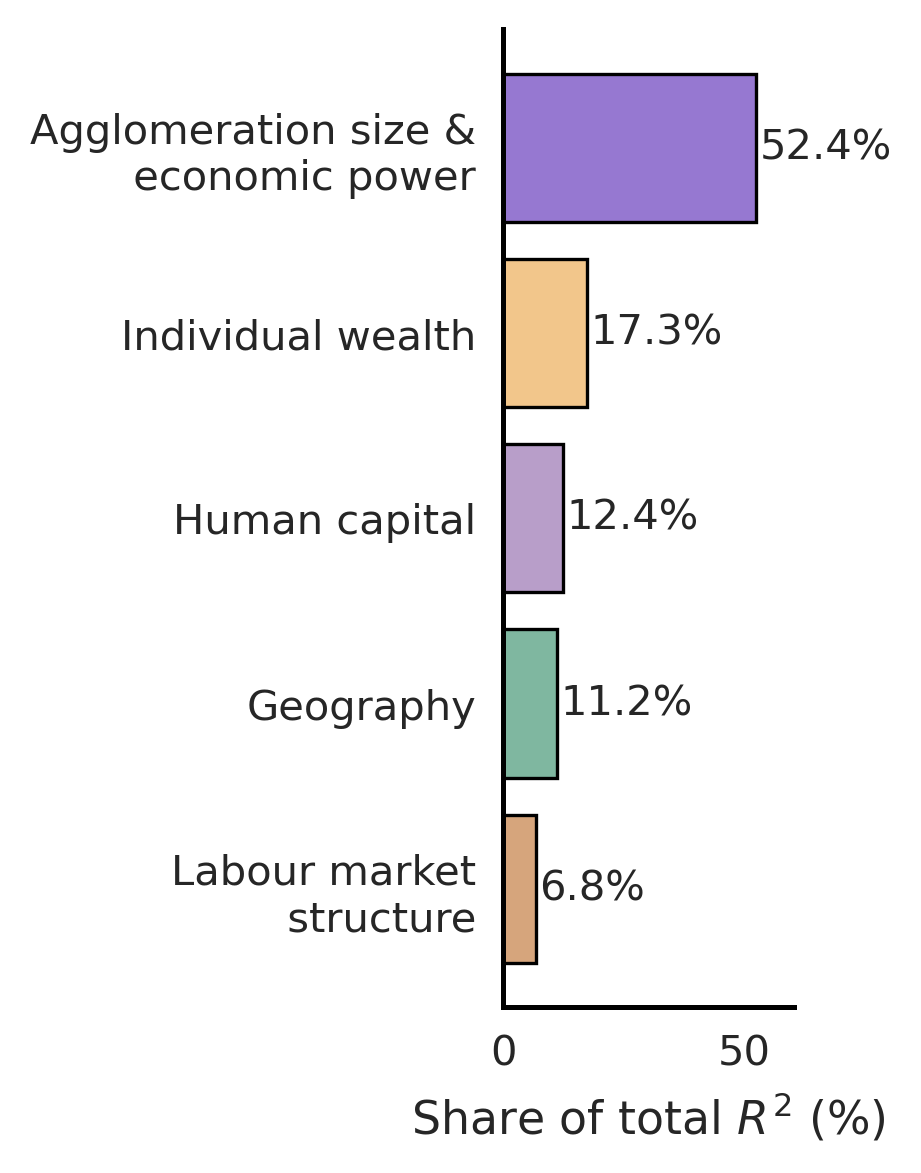

In [20]:
group_colors = {
    "Agglomeration size &\n economic power": "#9678D1",  # muted violet
    "Geography": "#7FB7A0",                              # sage green
    "Labour market\n structure": "#D6A57C",             # warm sand
    "Human capital": "#B89EC9",                          # lavender
    "Individual wealth": "#F2C68B"                       # soft amber
}

fig, ax = plt.subplots(figsize=(3, 4))

results = results.sort_values("Share of total R2 (%)", ascending=True)

ax.barh(
    results["Group"],
    results["Share of total R2 (%)"],
    color=results["Group"].map(group_colors),
    edgecolor="black",
    linewidth=0.8
)

for i, v in enumerate(results["Share of total R2 (%)"]):
    ax.text(
        v + 0.7,
        i,
        f"{v:.1f}%",
        va="center",
        fontsize=10
    )

# axis formatting
ax.set_xlabel("Share of total $R^2$ (%)")
ax.set_ylabel("")
ax.set_xlim(0, max(results["Share of total R2 (%)"]) * 1.15)

# remove grid, clean spines
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="both", which="major")

plt.tight_layout()
plt.show()

In [21]:
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from collections import defaultdict
import random

variables = [
    "log_pop_centered",
    "log_gdp_centered",
    "log_pop_centered:log_gdp_centered",
    "I(log_pop_centered ** 2)",
    "log_taxes_med_centered",
    "log_dividends_centered",
    "income_price_ratio2023_centered",
    "log_est_100k_centered",
    "log_emp_100k_centered",
    "log_n_postings_centered",
    "education_centered",
    "health_centered",
    "inequality_centered",
    "nat_amenity_centered",
    "water_perc_centered",
    "risk_centered",
]


def fit_r2(vars_subset, data):
    if len(vars_subset) == 0:
        return 0.0
    formula = "pagerank_logdiff ~ " + " + ".join(vars_subset)
    return smf.ols(formula, data=data).fit().rsquared


def shapley_one_permutation(variables, data, seed=None):
    if seed is not None:
        random.seed(seed)

    perm = variables.copy()
    random.shuffle(perm)

    contrib = defaultdict(float)
    included = []
    prev_r2 = 0.0

    for v in perm:
        included.append(v)
        r2_now = fit_r2(included, data)
        contrib[v] = r2_now - prev_r2
        prev_r2 = r2_now

    return contrib


n_permutations = 2000
n_jobs = 12

# run permutations in parallel
results_ind = Parallel(n_jobs=n_jobs)(
    delayed(shapley_one_permutation)(
        variables,
        df,
        seed=i
    )
    for i in tqdm(range(n_permutations), desc="Shapley permutations")
)

shapley = defaultdict(float)

for res in results_ind:
    for v, val in res.items():
        shapley[v] += val

# average over permutations
for v in shapley:
    shapley[v] /= n_permutations

Shapley permutations:   0%|          | 0/2000 [00:00<?, ?it/s]

In [22]:
R2_full = model_5.rsquared

shapley_var_df = (
    pd.DataFrame({
        "Variable": shapley.keys(),
        "Shapley R2": shapley.values()
    })
    .sort_values("Shapley R2", ascending=False)
    .reset_index(drop=True)
)

shapley_var_df["Share of total R2 (%)"] = (
    100 * shapley_var_df["Shapley R2"] / R2_full
)

shapley_var_df

,Variable,Shapley R2,Share of total R2 (%)
0,I(log_pop_centered ** 2),0.083230,18.670987
1,log_pop_centered:log_gdp_centered,0.071632,16.069246
2,log_dividends_centered,0.041690,9.352388
3,log_gdp_centered,0.040799,9.152505
4,log_pop_centered,0.032365,7.260396
5,income_price_ratio2023_centered,0.032174,7.217566
6,nat_amenity_centered,0.031382,7.039939
7,education_centered,0.026818,6.016137
8,log_est_100k_centered,0.016215,3.637551
9,risk_centered,0.014466,3.245138


In [23]:
print("Sum of Shapley R2:", shapley_var_df["Shapley R2"].sum())
print("Full model R2:", R2_full)

Sum of Shapley R2: 0.4457714237114236
Full model R2: 0.4457714237114233


In [24]:
groups = {
    "Agglomeration size &\n economic power": [
        "log_pop_centered", "log_gdp_centered",
        "log_pop_centered:log_gdp_centered", "I(log_pop_centered ** 2)"
    ],
    "Individual wealth": [
        "log_taxes_med_centered", "log_dividends_centered", "income_price_ratio2023_centered"
    ],
    "Human capital": [
        "education_centered", "health_centered", "inequality_centered"
    ],
    "Labour market\n structure": [
        "log_est_100k_centered", "log_emp_100k_centered", "log_n_postings_centered"
    ],
    "Geography": [
        "nat_amenity_centered", "water_perc_centered", "risk_centered"
    ]
}

var_to_group = {
    var: group
    for group, vars_in_group in groups.items()
    for var in vars_in_group
}

shapley_var_df["Group"] = shapley_var_df["Variable"].map(var_to_group)

# sort by partial R2
results = results.sort_values('Share of total R2 (%)', ascending=False)
group_order = (
    results.Group
)

# within each group: variables sorted by partial R2 (descending)
shapley_var_df["Group"] = pd.Categorical(shapley_var_df["Group"], categories=group_order, ordered=True)
shapley_var_df = shapley_var_df.sort_values(["Group", "Shapley R2"], ascending=[False, True]).reset_index(drop=True)

# y positions
shapley_var_df["y"] = np.arange(len(shapley_var_df))

var_labels = {
    "log_pop_centered": "Pop",
    "log_gdp_centered": "GDPpc",
    "log_pop_centered:log_gdp_centered": "Pop × GDPpc",
    "I(log_pop_centered ** 2)": "Pop²",
    "nat_amenity_centered": "Natural amenities",
    "risk_centered": "Hazard risk",
    "water_perc_centered": "Water share",
    "education_centered": "Education",
    "inequality_centered": "Inequality",
    "health_centered": "Health",
    "income_price_ratio2023_centered": "Price–income ratio",
    "log_taxes_med_centered": "Real estate taxes",
    "log_dividends_centered": "Dividends",
    "log_est_100k_centered": "Establishments",
    "log_emp_100k_centered": "Employment",
    "log_n_postings_centered": "Job postings",
}

shapley_var_df["label"] = shapley_var_df["Variable"].map(var_labels)

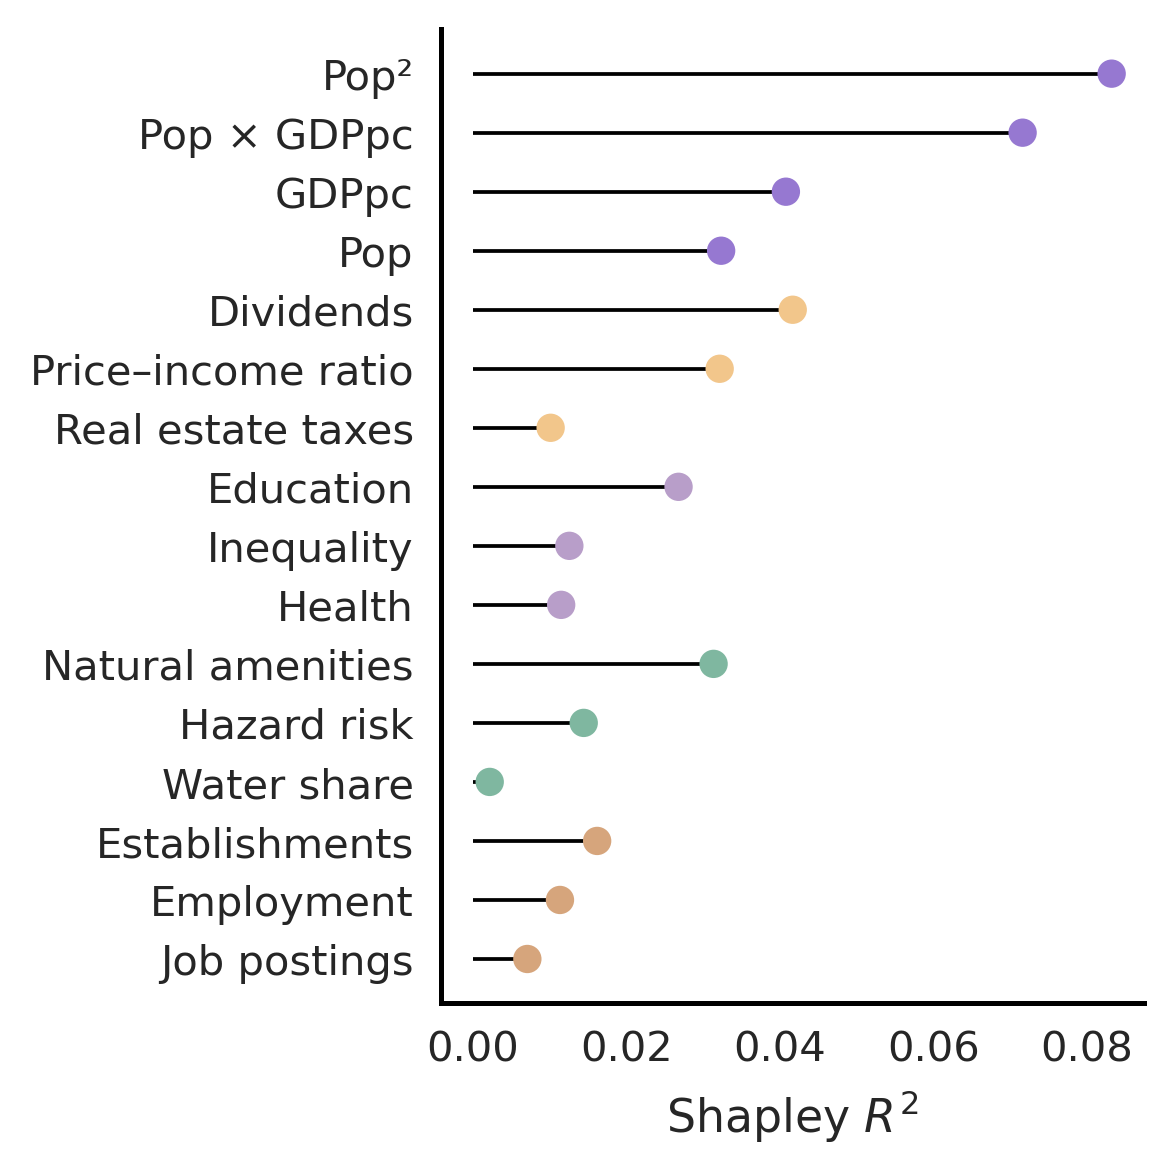

In [25]:
groups = shapley_var_df["Group"].unique()

fig, ax = plt.subplots(figsize=(4, 4))

# stems
ax.hlines(
    y=shapley_var_df["y"],
    xmin=0,
    xmax=shapley_var_df["Shapley R2"],
    color="black",
    linewidth=0.9
)

# heads (colored by group)
ax.scatter(
    shapley_var_df["Shapley R2"],
    shapley_var_df["y"],
    c=shapley_var_df["Group"].map(group_colors),
    s=36,
    zorder=3
)

# axis formatting
ax.set_xlabel("Shapley $R^2$")
ax.set_yticks(shapley_var_df["y"])
ax.set_yticklabels(shapley_var_df["label"])

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)


plt.tight_layout()
plt.show()

### Model 5 coefficients (CI dot plot)

In [26]:
import re

records = []
rows = df_results.reset_index()

for i in range(len(rows) - 1):

    var = rows.loc[i, "index"]
    coef_cell = rows.loc[i, "Model 5"]
    se_cell   = rows.loc[i + 1, "Model 5"]

    # coefficient rows are strings; SE rows start with "("
    if not isinstance(coef_cell, str):
        continue
    if not isinstance(se_cell, str) or not se_cell.startswith("("):
        continue
    if var in ["Intercept", "R-squared", "R-squared Adj.", "BIC", "N"]:
        continue

    coef = float(re.sub(r"[^\d\.\-]", "", coef_cell))
    se   = float(re.sub(r"[^\d\.\-]", "", se_cell))

    sig = re.sub(r"[\d\.\-\s]", "", coef_cell)   # keeps *, **, *** or +

    records.append({
        "Variable": var,
        "coef": coef,
        "se": se,
        "sig": sig
    })



coef_df = pd.DataFrame(records)

coef_df["ci_low"] = coef_df["coef"] - 1.96 * coef_df["se"]
coef_df["ci_high"] = coef_df["coef"] + 1.96 * coef_df["se"]

var_to_group = {
    "log_pop_centered": "Agglomeration size &\n economic power",
    "log_gdp_centered": "Agglomeration size &\n economic power",
    "log_pop_centered:log_gdp_centered": "Agglomeration size &\n economic power",
    "I(log_pop_centered ** 2)": "Agglomeration size &\n economic power",

    "log_taxes_med_centered": "Individual wealth",
    "log_dividends_centered": "Individual wealth",
    "income_price_ratio2023_centered": "Individual wealth",

    "log_est_100k_centered": "Labour market\n structure",
    "log_emp_100k_centered": "Labour market\n structure",
    "log_n_postings_centered": "Labour market\n structure",

    "education_centered": "Human capital",
    "health_centered": "Human capital",
    "inequality_centered": "Human capital",

    "nat_amenity_centered": "Geography",
    "water_perc_centered": "Geography",
    "risk_centered": "Geography"
}

coef_df["Group"] = coef_df["Variable"].map(var_to_group)
coef_df = coef_df.dropna(subset=["Group"])

In [27]:
var_name_map = {
    "log_pop_centered:log_gdp_centered": "Pop × GDPpc",
    "I(log_pop_centered ** 2)": "Pop²",
    "log_gdp_centered": "GDPpc",
    "log_pop_centered": "Pop",

    "nat_amenity_centered": "Natural amenities",
    "risk_centered": "Hazard risk",
    "log_pop_density_centered": "Pop density",
    "water_perc_centered": "Water share",

    "education_centered": "Education",
    "inequality_centered": "Inequality",
    "health_centered": "Health",

    "income_price_ratio2023_centered": "Price-income ratio",
    "log_taxes_med_centered": "Real estate taxes",
    "log_dividends_centered": "Dividends",

    "log_est_100k_centered": "Establishments",
    "log_emp_100k_centered": "Employment",
    "log_n_postings_centered": "Job postings"
}

coef_df["Variable_label"] = coef_df["Variable"].map(var_name_map)

variable_order = shapley_var_df['Variable']

coef_df["Variable"] = pd.Categorical(
    coef_df["Variable"],
    categories=variable_order,
    ordered=True
)

coef_df = coef_df.sort_values("Variable").reset_index(drop=True)
coef_df["y"] = range(len(coef_df))

In [28]:
group_colors = {
    "Agglomeration size &\n economic power": "#9678D1",  # muted violet
    "Geography": "#7FB7A0",                              # sage green
    "Labour market\n structure": "#D6A57C",             # warm sand
    "Human capital": "#B89EC9",                          # lavender
    "Individual wealth": "#F2C68B"                       # soft amber
}

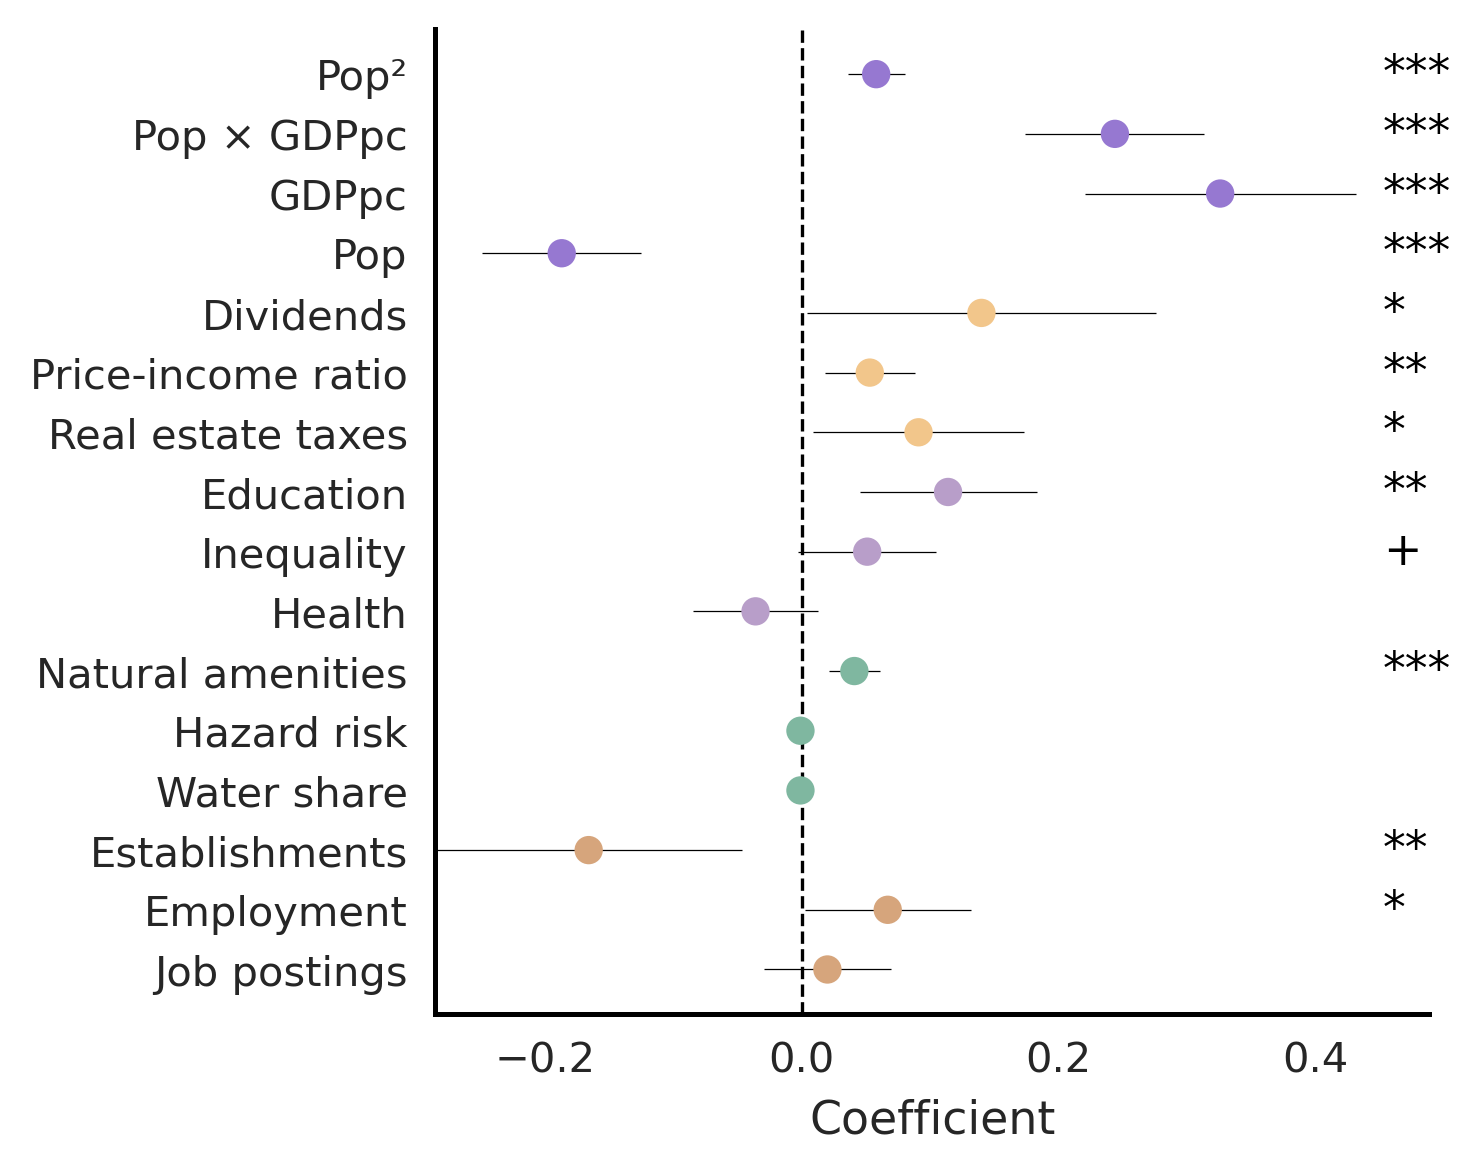

In [29]:
fig, ax = plt.subplots(figsize=(5, 4))

# confidence intervals
ax.hlines(
    y=coef_df["y"],
    xmin=coef_df["ci_low"],
    xmax=coef_df["ci_high"],
    color="black",
    linewidth=0.3
)

# point estimates
ax.scatter(
    coef_df["coef"],
    coef_df["y"],
    c=coef_df["Group"].map(group_colors),
    s=36,
    zorder=3
)

# zero line
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)

ax.set_yticks(coef_df["y"])
ax.set_yticklabels(coef_df["Variable_label"])

ax.set_xlabel("Coefficient")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)

sig_x = coef_df["ci_high"].max() + 0.03 * (
    coef_df["ci_high"].max() - coef_df["ci_low"].min()
)

for _, row in coef_df.iterrows():
    if row["sig"] != "":
        ax.text(
            sig_x,
            row["y"],
            row["sig"],
            fontsize=11,
            va="center",
            ha="left",
            color="black",
            zorder=4
        )

ax.set_xlim(
    coef_df["ci_low"].min(),
    sig_x + 0.05 * (coef_df["ci_high"].max() - coef_df["ci_low"].min())
)


plt.tight_layout()
plt.show()

### For SI: spatial and network dependence

Counties, like the CBSAs in the companion notebook, are unlikely to be independent observations. This section:

1. Builds county spatial weights (queen contiguity and a 200km distance band) and tests `model_5`'s residuals for spatial autocorrelation under both.
2. Re-estimates `model_5` with Conley (1999) spatial-HAC SEs and compares them against HC3 and the state-clustered baseline used throughout this notebook. No state-cluster approximation is needed, since `STATEFP` nests counties exactly.
3. Repeats that comparison for the two most significant individual hazards from the per-hazard OLS section below.
4. Carries over the note on PageRank's compositional structure, which is a property of the network rather than of either geography.

In [30]:
from utils import (
    build_county_geometry, cbsa_centroid_xy, build_county_weights,
    morans_i_report, conley_hac_from_model, coef_comparison_table,
)
import libpysal
import esda

In [31]:
county_order = df['STCOFIPS'].astype(str).tolist()
county_gdf = build_county_geometry(county_order)
coords_xy = cbsa_centroid_xy(county_gdf)

# Alignment is the single highest-risk correctness issue here: the weights
# matrices built below must be in exactly the same county order as df/model_5.
assert county_gdf['STCOFIPS'].tolist() == county_order, "County geometry row order does not match df"
assert len(coords_xy) == len(df) == len(model_5.resid)
print(f"County geometry aligned to df/model_5: N={len(county_order)}")

County geometry aligned to df/model_5: N=1989


In [32]:
weights = build_county_weights(county_gdf, county_order, distance_band_km=200)

/mnt/sdb1/timur/anaconda3/lib/python3.11/site-packages/libpysal/weights/contiguity.py:347: UserWarning: The weights matrix is not fully connected: 
 There are 41 disconnected components.
 There are 21 islands with ids: 08099, 25007, 25019, 26033, 27075, 30017, 30021, 31033, 40065, 46005, 46023, 46029, 46035, 46129, 48273, 51099, 51125, 51133, 53055, 54013, 54071.
  W.__init__(self, neighbors, ids=ids, **kw)
/mnt/sdb1/timur/anaconda3/lib/python3.11/site-packages/libpysal/weights/util.py:819: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
 There is 1 island with id: 32023.
  w = W(neighbors, weights, ids, **kwargs)


Queen contiguity: 21 island county(ies) with zero neighbors: ['08099', '25007', '25019', '26033', '27075', '30017', '30021', '31033', '40065', '46005', '46023', '46029', '46035', '46129', '48273', '51099', '51125', '51133', '53055', '54013', '54071']
Distance band (200km): 1 island county(ies) with zero neighbors: ['32023']


/mnt/sdb1/timur/anaconda3/lib/python3.11/site-packages/libpysal/weights/distance.py:855: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
 There is 1 island with id: 32023.
  W.__init__(


**Moran's I on `model_5` residuals**

In [33]:
resid = pd.Series(model_5.resid.values, index=county_order)

moran_queen = morans_i_report(resid, weights["queen"][0], weights["queen"][1], label="Queen contiguity")
moran_db = morans_i_report(resid, weights["distance_band"][0], weights["distance_band"][1], label="Distance band (200km)")

# Sanity check: Moran's I on randomly permuted residuals should cluster near
# zero and be mostly non-significant -- confirms the test itself behaves
# correctly before trusting the real-residual numbers above.
print("\nSanity check -- Moran's I on 3 random permutations of the same residuals:")
rng = np.random.RandomState(0)
for i in range(3):
    shuffled = pd.Series(rng.permutation(resid.values), index=county_order)
    morans_i_report(shuffled, weights["queen"][0], weights["queen"][1], label=f"  shuffle {i}")

/mnt/sdb1/timur/anaconda3/lib/python3.11/site-packages/libpysal/weights/set_operations.py:386: UserWarning: The weights matrix is not fully connected: 
 There are 20 disconnected components.
  return W(neighbors, id_order=list(ids), **kwargs)


Moran's I [Queen contiguity]: I=0.2535  p_sim=0.0010  p_norm=0.0000  (N=1968, 21 islands dropped)
Moran's I [Distance band (200km)]: I=0.1065  p_sim=0.0010  p_norm=0.0000  (N=1988, 1 islands dropped)

Sanity check -- Moran's I on 3 random permutations of the same residuals:
Moran's I [  shuffle 0]: I=-0.0265  p_sim=0.0519  p_norm=0.1177  (N=1968, 21 islands dropped)
Moran's I [  shuffle 1]: I=-0.0227  p_sim=0.0979  p_norm=0.1809  (N=1968, 21 islands dropped)


/mnt/sdb1/timur/anaconda3/lib/python3.11/site-packages/libpysal/weights/set_operations.py:386: UserWarning: The weights matrix is not fully connected: 
 There are 20 disconnected components.
  return W(neighbors, id_order=list(ids), **kwargs)
/mnt/sdb1/timur/anaconda3/lib/python3.11/site-packages/libpysal/weights/set_operations.py:386: UserWarning: The weights matrix is not fully connected: 
 There are 20 disconnected components.
  return W(neighbors, id_order=list(ids), **kwargs)
/mnt/sdb1/timur/anaconda3/lib/python3.11/site-packages/libpysal/weights/set_operations.py:386: UserWarning: The weights matrix is not fully connected: 
 There are 20 disconnected components.
  return W(neighbors, id_order=list(ids), **kwargs)


Moran's I [  shuffle 2]: I=0.0003  p_sim=0.4995  p_norm=0.9619  (N=1968, 21 islands dropped)


**Conley (1999) spatial-HAC standard errors**

`utils.conley_hac_se` hand-codes the sandwich estimator directly:

V = (X'X)^-1 (X' &Omega; X) (X'X)^-1, where &Omega;_ij = resid_i &middot; resid_j &middot; 1(dist_ij &le; 200km)

using a uniform (binary) kernel with the same 200km cutoff as the distance-band weights above, for internal consistency. No small-sample degrees-of-freedom correction is applied.

In [34]:
conley = conley_hac_from_model(model_5, coords_xy, cutoff=200_000, kernel="uniform")
print(f"risk_centered: coef={model_5.params['risk_centered']:.5f}  "
      f"state-cluster se={model_5.bse['risk_centered']:.5f}  "
      f"Conley-HAC se={conley['se']['risk_centered']:.5f}")

risk_centered: coef=-0.00102  state-cluster se=0.00107  Conley-HAC se=0.00109


In [35]:
model_5_hc3 = smf.ols(formula=model_5.model.formula, data=df).fit(cov_type='HC3')

coef_table = coef_comparison_table(
    model_5.params,
    {
        "HC3": model_5_hc3.bse,
        "Conley-HAC (200km)": conley["se"],
        "State-cluster (baseline)": model_5.bse,
    },
)
coef_table

,coef,HC3_se,HC3_p,HC3_stars,Conley-HAC (200km)_se,Conley-HAC (200km)_p,Conley-HAC (200km)_stars,State-cluster (baseline)_se,State-cluster (baseline)_p,State-cluster (baseline)_stars
param,,,,,,,,,,
Intercept,-0.769106,0.013161,0.000000e+00,***,0.028734,0.000000e+00,***,0.027997,0.000000e+00,***
log_pop_centered,-0.186675,0.016778,0.000000e+00,***,0.024820,5.440093e-14,***,0.031619,3.548461e-09,***
log_gdp_centered,0.326451,0.047920,9.596102e-12,***,0.046517,2.253309e-12,***,0.053834,1.327959e-09,***
log_pop_centered:log_gdp_centered,0.244286,0.030198,6.661338e-16,***,0.031675,1.243450e-14,***,0.035599,6.781464e-12,***
I(log_pop_centered ** 2),0.058014,0.007192,6.661338e-16,***,0.009950,5.525724e-09,***,0.011445,4.001536e-07,***
log_taxes_med_centered,0.090797,0.022513,5.506336e-05,***,0.036575,1.304686e-02,*,0.041860,3.007723e-02,*
log_dividends_centered,0.139592,0.060170,2.034219e-02,*,0.069239,4.379175e-02,*,0.069201,4.367443e-02,*
income_price_ratio2023_centered,0.052736,0.012335,1.909020e-05,***,0.019742,7.557314e-03,**,0.017905,3.227134e-03,**
log_est_100k_centered,-0.166115,0.052844,1.669458e-03,**,0.049975,8.875493e-04,***,0.061059,6.517005e-03,**


### Spatial and network-robust SEs for the two most significant individual hazards

Hurricane (`HRCN`) and heat wave (`HWAV`) are the two most significant individual hazards in the per-hazard OLS section below. Coastal flooding (`CFLD`) is close but rests on a much smaller effective sample (N=346 against N>=1475 for HRCN and HWAV), so it is left out here. Model 5 is refit for each, with `risk_centered` replaced by the hazard-specific capacity-purged EAL score (`HRCN_EALS_centered`, `HWAV_EALS_centered`), comparing the state-clustered baseline against HC3 and Conley spatial-HAC (200km).

In [36]:
# Self-contained: build HRCN_EALS / HWAV_EALS at county level directly from the
# NRI shapefile (no CBSA aggregation needed), without depending on the
# "For SI: OLS per individual climate hazard" section below having run yet.
gdf_eals = gpd.read_file("../data_loaded/NRI_Shapefile_Counties/NRI_Shapefile_Counties.shp", ignore_geometry=True)
eals = gdf_eals[["STCOFIPS", "HRCN_EALS", "HWAV_EALS"]].replace(-9999, np.nan)
for c in ["HRCN_EALS", "HWAV_EALS"]:
    eals[c] = pd.to_numeric(eals[c], errors="coerce")
eals["STCOFIPS"] = eals["STCOFIPS"].astype(str).str.zfill(5)

df_eals = df.merge(eals, on="STCOFIPS", how="left", suffixes=("", "_eals"))

df_eals["HRCN_EALS_centered"] = df_eals["HRCN_EALS"] - df_eals["HRCN_EALS"].mean()
df_eals["HWAV_EALS_centered"] = df_eals["HWAV_EALS"] - df_eals["HWAV_EALS"].mean()

perhazard_spatial_rows = []
for hz, term in [("HRCN", "HRCN_EALS_centered"), ("HWAV", "HWAV_EALS_centered")]:
    mask = df_eals[term].notna()
    sub = df_eals.loc[mask]
    coords_sub = coords_xy[mask.values]

    formula_hz = (
        f"pagerank_logdiff ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
        f"+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
        f"+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
        f"+ education_centered + health_centered + inequality_centered"
        f"+ nat_amenity_centered + water_perc_centered + {term}"
    )
    m_hc3 = smf.ols(formula=formula_hz, data=sub).fit(cov_type='HC3')
    m_sc = smf.ols(formula=formula_hz, data=sub).fit(cov_type='cluster', cov_kwds={'groups': sub['STATEFP']})
    conley_hz = conley_hac_from_model(m_hc3, coords_sub, cutoff=200_000, kernel="uniform")

    for method, se, p in [
        ("HC3", m_hc3.bse[term], m_hc3.pvalues[term]),
        ("Conley-HAC (200km)", conley_hz["se"][term], conley_hz["p"][term]),
        ("State-cluster (baseline)", m_sc.bse[term], m_sc.pvalues[term]),
    ]:
        perhazard_spatial_rows.append({
            "hazard": hz, "method": method, "coef": m_hc3.params[term],
            "se": se, "p": p, "stars": make_stars(p), "N": int(m_hc3.nobs),
        })

perhazard_spatial = pd.DataFrame(perhazard_spatial_rows)
perhazard_spatial

,hazard,method,coef,se,p,stars,N
0,HRCN,HC3,0.002759,0.000533,2.239992e-07,***,1475
1,HRCN,Conley-HAC (200km),0.002759,0.000969,4.416869e-03,**,1475
2,HRCN,State-cluster (baseline),0.002759,0.000809,6.533276e-04,***,1475
3,HWAV,HC3,-0.001624,0.000370,1.155408e-05,***,1989
4,HWAV,Conley-HAC (200km),-0.001624,0.000694,1.935957e-02,*,1989
5,HWAV,State-cluster (baseline),-0.001624,0.000613,8.091144e-03,**,1989


### PageRank's compositional structure

Within each window every county's PageRank is computed from the same global transition matrix, and the values sum to one across all counties. A change in one county's PageRank therefore implies offsetting changes elsewhere, independent of geographic proximity. The log-ratio transform used for the outcome variables addresses the scale and multiplicative-error issues that come with ratio-like quantities, but it does not remove this simplex dependence: log-ratios of a composition remain defined relative to the same whole, so observations stay coupled through the network's global structure.

### For SI: capacity-purged hazard measures

- Full-hazard EAL (`EAL_SCORE`): the NRI's composite Expected-Annual-Loss percentile score, upstream of the Social Vulnerability and Community Resilience multipliers, over the same 18 hazards as `RISK_SCORE`.
- Climate-only composite: the mean of the 13 climate-relevant `EALS` scores (`RFLD, CFLD, HWAV, CWAV, DRGT, HRCN, TRND, HAIL, LTNG, SWND, WFIR, WNTW, ISTM`), each already normalised to 0-100. The five geophysical hazards (`ERQK, VLCN, TSUN, LNDS, AVLN`) are excluded.

This is the same hazard set as the composite in `3_modelling_pr_cbsa.ipynb` and as the per-hazard section below, so the CBSA and county climate-only specifications are comparable.

Both fields come straight from the NRI county shapefile and merge onto `df` by `STCOFIPS`, with no aggregation step.

In [37]:
# The 13 climate-relevant hazards, matching CLIMATE_HAZARDS in the per-hazard
# section below and the composite used in 3_modelling_pr_cbsa.ipynb.
# LNDS (landslide) and AVLN (avalanche) are geophysical and are excluded here,
# alongside ERQK, VLCN and TSUN.
CLIMATE_HAZARDS_EAL = ["RFLD", "CFLD", "HWAV", "CWAV", "DRGT", "HRCN", "TRND",
                       "HAIL", "LTNG", "SWND", "WFIR", "WNTW", "ISTM"]

eal_cols_wanted = ["STCOFIPS", "EAL_SCORE"] + [f"{h}_EALS" for h in CLIMATE_HAZARDS_EAL]

gdf_eal = gpd.read_file("../data_loaded/NRI_Shapefile_Counties/NRI_Shapefile_Counties.shp", ignore_geometry=True)
eal_cols = [c for c in eal_cols_wanted if c in gdf_eal.columns]
eal = gdf_eal[eal_cols].replace(-9999, np.nan)
for c in eal.columns:
    if c != "STCOFIPS":
        eal[c] = pd.to_numeric(eal[c], errors="coerce")

# mean of per-hazard normalized EALS scores
score_cols = [f"{h}_EALS" for h in CLIMATE_HAZARDS_EAL if f"{h}_EALS" in eal.columns]
eal["climate_eal_meanscore"] = eal[score_cols].mean(axis=1, skipna=True)

eal["STCOFIPS"] = eal["STCOFIPS"].astype(str).str.zfill(5)

NEW_MEASURES = ["EAL_SCORE", "climate_eal_meanscore"]
eal_slim = eal[["STCOFIPS"] + NEW_MEASURES]
print("County-level new-measures table:", eal_slim.shape)

County-level new-measures table: (3231, 3)


In [38]:
df = df.merge(eal_slim, on="STCOFIPS", how="left", suffixes=("", "_y"))
for m in NEW_MEASURES:
    df[f"{m}_centered"] = df[m] - df[m].mean()

print(f"Regression sample after merging new hazard measures: N={len(df)} "
      f"(unchanged from the RISK_SCORE-only sample -- no new missingness)")
print()
print("Correlation matrix across hazard measures (county level, N=%d):" % len(df))
print(df[["RISK_SCORE"] + NEW_MEASURES].corr().round(3).to_string())

Regression sample after merging new hazard measures: N=1989 (unchanged from the RISK_SCORE-only sample -- no new missingness)

Correlation matrix across hazard measures (county level, N=1989):
                       RISK_SCORE  EAL_SCORE  climate_eal_meanscore
RISK_SCORE                  1.000      0.990                  0.688
EAL_SCORE                   0.990      1.000                  0.713
climate_eal_meanscore       0.688      0.713                  1.000


In [39]:
MODEL_5_BASE = (
    "pagerank_logdiff ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
    "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
    "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
    "+ education_centered + health_centered + inequality_centered"
    "+ nat_amenity_centered + water_perc_centered + {hazard_term}"
)

specs = {
    "RISK_SCORE (existing headline)": "risk_centered",
    "EAL_SCORE (full-hazard EAL)": "EAL_SCORE_centered",
    "Climate-only (mean-score)": "climate_eal_meanscore_centered",
}

print(f"{'Spec':32s} {'hazard coef':>14s} {'SE':>10s} {'p':>8s} {'N':>6s} {'R2':>6s}")
for name, term in specs.items():
    formula = MODEL_5_BASE.format(hazard_term=term)
    sub = df.dropna(subset=[term])
    m = smf.ols(formula=formula, data=sub).fit(cov_type='cluster', cov_kwds={'groups': sub['STATEFP']})
    est = m.params[term]
    se = m.bse[term]
    p = m.pvalues[term]
    print(f"{name:32s} {est: 14.5f} {se:10.5f} {p:8.4f} {int(m.nobs):6d} {m.rsquared:6.3f}")

Spec                                hazard coef         SE        p      N     R2
RISK_SCORE (existing headline)         -0.00102    0.00107   0.3407   1989  0.446
EAL_SCORE (full-hazard EAL)            -0.00145    0.00103   0.1594   1989  0.447
Climate-only (mean-score)              -0.00471    0.00178   0.0083   1989  0.450


### Causal forest ATE across the same three hazard measures

County-level analogue of `hazard_measure_comparison.R`: the same median-split binary-treatment causal forest, run for `RISK_SCORE`, `EAL_SCORE` and the climate-only composite via `scripts_causal_forest/hazard_measure_comparison_county.R`. Run that script separately; its output goes to `../data_generated/cf_results/county/hazard_measure_comparison.csv`. Forests here are clustered by state, as in the other county scripts, and cover the pooled 2011-2022 sample only.

In [40]:
hazard_measure_comparison_county = pd.read_csv('../data_generated/cf_results/county/hazard_measure_comparison.csv')
hazard_measure_comparison_county['stars'] = hazard_measure_comparison_county['ATE_p'].apply(make_stars)
hazard_measure_comparison_county

,period,hazard,n_total,n_keep,ATE_est,ATE_se,ATE_p,stars
0,2011-2022,RISK_SCORE,1989,1799,-0.078530,0.032747,0.016482,*
1,2011-2022,EAL_SCORE,1989,1787,-0.049006,0.032738,0.134418,
2,2011-2022,climate_eal_meanscore,1989,1881,-0.098325,0.030553,0.001290,**


### For SI: OLS per individual climate hazard

Refits Model 5 separately for each climate hazard's individual EAL score (`<HAZ>_EALS`, capacity-purged) instead of the composite, to see whether compositing dilutes a signal from specific hazards.

The per-hazard `EALS` fields are native to the NRI county shapefile, so they merge onto `df` by `STCOFIPS` with no aggregation. Pooled 2011-2022 sample only; the CBSA notebook's 2011-2019 companion check is not reproduced here.

In [41]:
CLIMATE_HAZARDS = ["RFLD", "CFLD", "HWAV", "CWAV", "DRGT", "HRCN", "TRND",
                   "HAIL", "LTNG", "SWND", "WFIR", "WNTW", "ISTM"]

eal_cols_wanted = ["STCOFIPS"] + [f"{h}_EALS" for h in CLIMATE_HAZARDS]

gdf = gpd.read_file("../data_loaded/NRI_Shapefile_Counties/NRI_Shapefile_Counties.shp", ignore_geometry=True)
eal_cols = [c for c in eal_cols_wanted if c in gdf.columns]
eal = gdf[eal_cols].replace(-9999, np.nan)
for c in eal.columns:
    if c != "STCOFIPS":
        eal[c] = pd.to_numeric(eal[c], errors="coerce")

eal["STCOFIPS"] = eal["STCOFIPS"].astype(str).str.zfill(5)

df = df.merge(eal, on="STCOFIPS", how="left", suffixes=("", "_y"))

print("Regression sample after merging per-hazard EALS:", len(df))
print("Missing per-hazard EALS counts:")
print(df[[f"{h}_EALS" for h in CLIMATE_HAZARDS if f"{h}_EALS" in df.columns]].isna().sum())

Regression sample after merging per-hazard EALS: 1989
Missing per-hazard EALS counts:
RFLD_EALS       0
CFLD_EALS    1643
HWAV_EALS       0
CWAV_EALS       0
DRGT_EALS       0
HRCN_EALS     514
TRND_EALS       0
HAIL_EALS       0
LTNG_EALS       0
SWND_EALS       0
WFIR_EALS       0
WNTW_EALS       0
ISTM_EALS     104
dtype: int64


In [42]:
MODEL_5_BASE = (
    "pagerank_logdiff ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
    "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
    "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
    "+ education_centered + health_centered + inequality_centered"
    "+ nat_amenity_centered + water_perc_centered + {hazard_term}"
)

def run_perhazard(pdf, label):
    rows = []
    for h in CLIMATE_HAZARDS:
        col = f"{h}_EALS"
        if col not in pdf.columns:
            continue
        term = f"{col}_centered"
        pdf[term] = pdf[col] - pdf[col].mean()
        formula = MODEL_5_BASE.format(hazard_term=term)
        sub = pdf.dropna(subset=[term])
        m = smf.ols(formula=formula, data=sub).fit(
            cov_type='cluster', cov_kwds={'groups': sub['STATEFP']}
        )
        rows.append({"period": label, "hazard": h, "coef": m.params[term],
                     "se": m.bse[term], "p": m.pvalues[term], "N": int(m.nobs)})
    return pd.DataFrame(rows)

perhazard = run_perhazard(df, "2011-2022")

def stars(p):
    if p < 0.001: return "***"
    if p < 0.01: return "**"
    if p < 0.05: return "*"
    if p < 0.1: return "."
    return ""

print(f"{'Hazard':8s} {'Period':10s} {'coef':>10s} {'p':>8s} {'N':>5s}")
for h in CLIMATE_HAZARDS:
    sub = perhazard[perhazard["hazard"] == h]
    if sub.empty:
        continue
    for _, r in sub.iterrows():
        print(f"{h:8s} {r['period']:10s} {r['coef']: 10.5f}{stars(r['p']):3s} {r['p']:8.4f} {int(r['N']):5d}")

Hazard   Period           coef        p     N
RFLD     2011-2022    -0.00105.     0.0820  1989
CFLD     2011-2022    -0.00196*     0.0461   346
HWAV     2011-2022    -0.00162**    0.0081  1989
CWAV     2011-2022     0.00032      0.6495  1989
DRGT     2011-2022    -0.00023      0.6747  1989
HRCN     2011-2022     0.00276***   0.0007  1475
TRND     2011-2022    -0.00035      0.7752  1989
HAIL     2011-2022    -0.00125*     0.0273  1989
LTNG     2011-2022    -0.00082      0.2617  1989
SWND     2011-2022    -0.00089      0.2438  1989
WFIR     2011-2022    -0.00010      0.8978  1989
WNTW     2011-2022    -0.00141.     0.0536  1989
ISTM     2011-2022    -0.00039      0.5489  1885


### Save for R (causal forest, run separately)

Saves the merged county table for the causal-forest scripts below, which are run **outside this notebook** (same pattern as the CBSA pipeline):

```
/path/to/Rscript scripts_causal_forest/loop_causal_forest_county.R
/path/to/Rscript scripts_causal_forest/causal_forest_continuous_county.R
/path/to/Rscript scripts_causal_forest/causal_forest_placebo_county.R
```

each writing its output CSVs to `data_generated/cf_results/county/`. Re-run the cells below once those finish.

In [43]:
df.to_csv('../data_generated/df_merged_county.csv')
print("df_merged_county.csv rows:", len(df))


df_merged_county.csv rows: 1989


## Causal forest results (county level)

Run `loop_causal_forest_county.R`, `causal_forest_continuous_county.R` and `causal_forest_placebo_county.R` first; they write to `../data_generated/cf_results/county/`. The plotting code is taken from `4_causal_inference.ipynb` and pointed at the county-level CSVs, with `STCOFIPS` as the unit id in place of `CBSA`.

### ATE across all hazards (binary treatment)

In [44]:
results_all=pd.read_csv('../data_generated/cf_results/county/cf_summary.csv')


In [45]:
df = results_all.copy()

df["hazard"] = df["hazard"].map(NRI_HAZARD_NAMES)


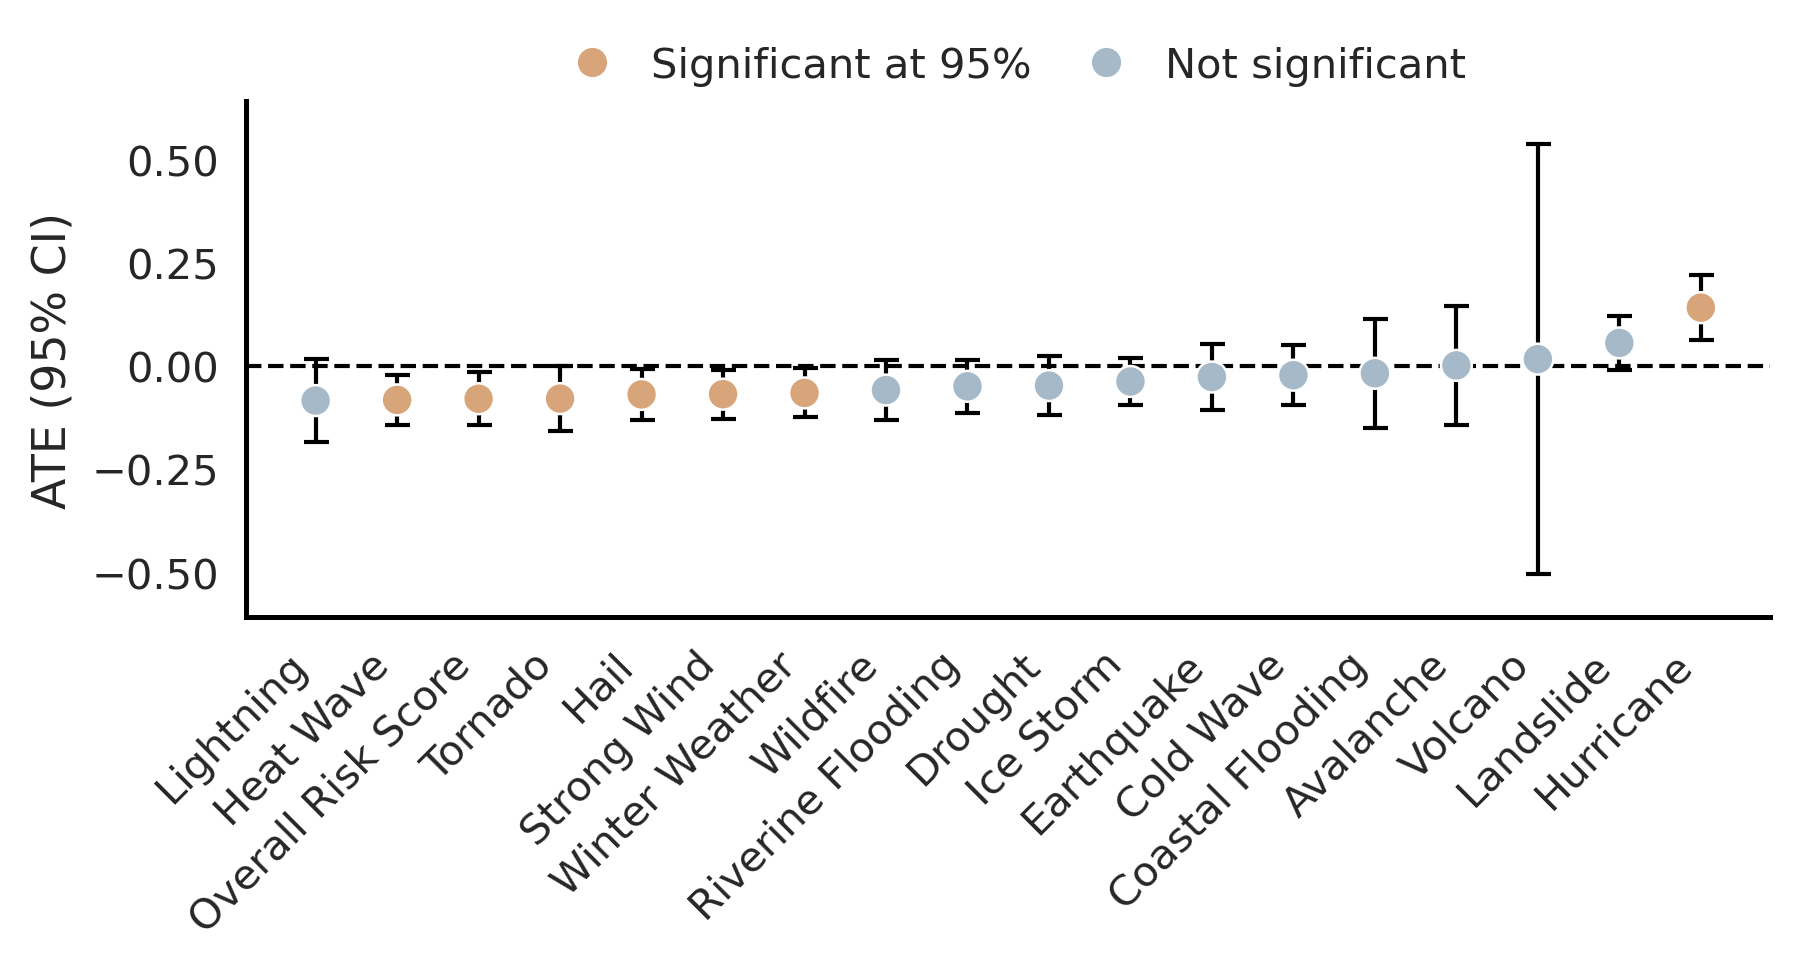

In [46]:
# keep hazards with ATE estimates
df = df[["hazard", "ATE_est", "ATE_se", "ATE_p"]].dropna().copy()

# 95% CI
z95 = 1.96
df["ci95_low"]  = df["ATE_est"] - z95 * df["ATE_se"]
df["ci95_high"] = df["ATE_est"] + z95 * df["ATE_se"]

# significance at 95%: CI excludes 0
df["sig95"] = (df["ci95_low"] > 0) | (df["ci95_high"] < 0)

# sort left->right by ATE
df = df.sort_values("ATE_est", ascending=True).reset_index(drop=True)

x = np.arange(len(df))

# ---- plot ----
fig, ax = plt.subplots(figsize=(6, 3.5))

# colors (muted)
c_nonsig = "#A5B9C8"  # muted blue
c_sig    = "#D8A57A"  # muted orange

colors = np.where(df["sig95"], c_sig, c_nonsig)

# vertical CI bars (because disasters are on x-axis)
yerr = z95 * df["ATE_se"].to_numpy()

ax.errorbar(
    x=x,
    y=df["ATE_est"].to_numpy(),
    yerr=yerr,
    fmt="o",
    markersize=6,
    capsize=3,
    linewidth=1,
    color="black",
    ecolor="black",
    zorder=2
)

# overlay colored points to indicate significance
ax.scatter(
    x,
    df["ATE_est"].to_numpy(),
    s=55,
    c=colors,
    edgecolors="white",
    linewidths=0.6,
    zorder=3
)

# zero line
ax.axhline(0, linewidth=1.0, linestyle="--", color="black")

# x labels (hazards)
ax.set_xticks(x)
ax.set_xticklabels(df["hazard"], rotation=45, ha="right")

ax.set_ylabel("ATE (95% CI)")

# y-limits with padding
ymin = (df["ci95_low"]).min()
ymax = (df["ci95_high"]).max()
pad = 0.10 * (ymax - ymin) if ymax > ymin else 0.1
ax.set_ylim(ymin - pad, ymax + pad)

# minimalist styling
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)

# legend (top, horizontal)
from matplotlib.lines import Line2D
handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor=c_sig, markeredgecolor="white",
           markersize=8, label="Significant at 95%"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor=c_nonsig, markeredgecolor="white",
           markersize=8, label="Not significant")
]
ax.legend(
    handles=handles,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.18),
    ncol=2,
    columnspacing=0.8,
    handletextpad=0.4
)

plt.tight_layout()
plt.show()


### RISK_SCORE: CATE distribution (binary treatment)

In [47]:
cates_all=pd.read_csv('../data_generated/cf_results/county/cf_cates.csv')
cates_all=cates_all[cates_all['hazard']=='RISK_SCORE']


In [48]:
vmax = cates_all["cate"].abs().quantile(0.95)
vmin = -vmax

norm = TwoSlopeNorm(
    vmin=vmin,
    vcenter=0.0,
    vmax=vmax
)


/tmp/ipykernel_30149/253811311.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = mpl.cm.get_cmap("RdYlBu_r")


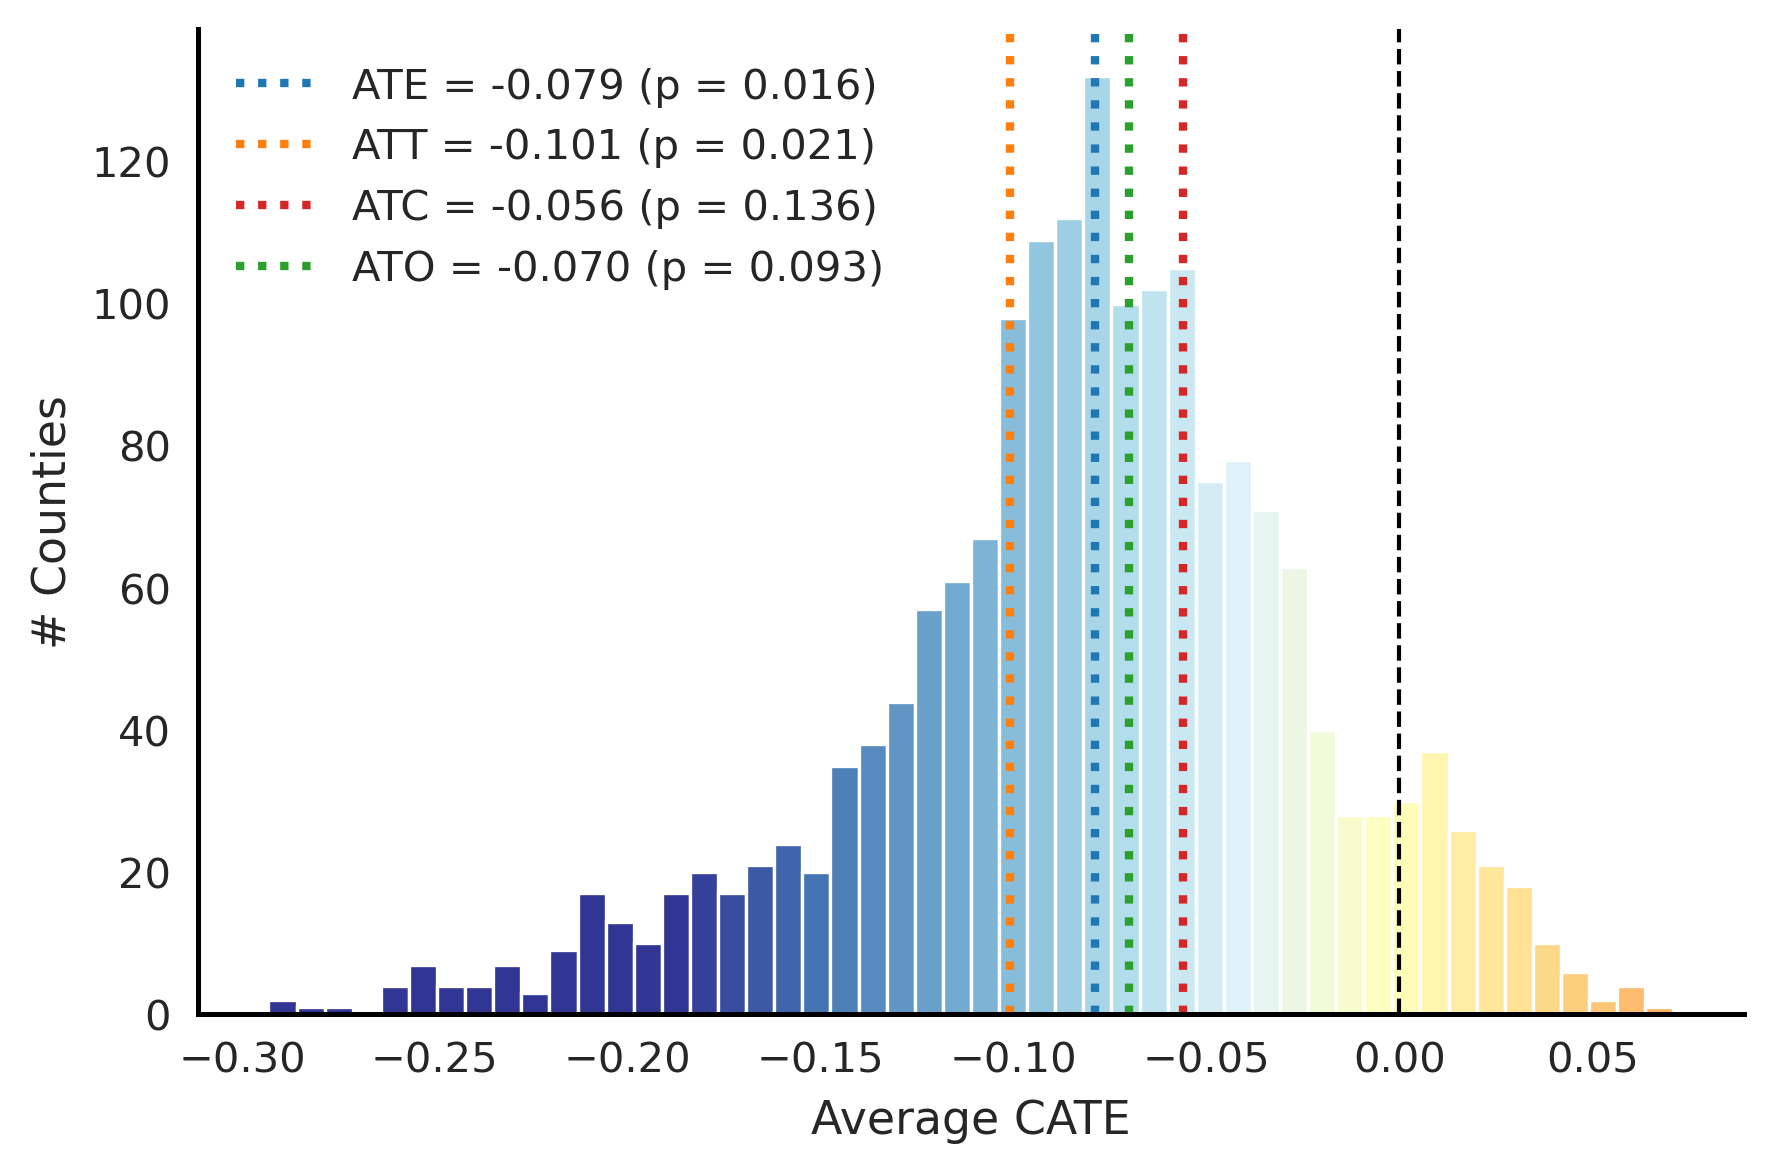

In [49]:
fig, ax = plt.subplots(figsize=(6, 4))

vals = cates_all["cate"].values

counts, bin_edges = np.histogram(vals, bins=50)

# compute bin midpoints (for color mapping)
bin_mids = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# get colors using the SAME norm + cmap as your colorbar
cmap = mpl.cm.get_cmap("RdYlBu_r")
colors = cmap(norm(bin_mids))

# plot histogram bars one by one
for left, height, width, color in zip(bin_edges[:-1], counts,
                                      np.diff(bin_edges), colors):
    ax.bar(left, height, width=width,
           color=color, edgecolor="white")

# zero line
ax.axvline(0, color="black", linewidth=1, linestyle="--")

ate=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATE_est'].iloc[0], 3)
p_val=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATE_p'].iloc[0], 3)
ax.axvline(ate, lw=2, linestyle=":",
           label=f"ATE = {ate:.3f} (p = {p_val:.3f})",
           color="tab:blue")

att=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATT_est'].iloc[0], 3)
p_val=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATT_p'].iloc[0], 3)
ax.axvline(att, lw=2, linestyle=":",
           label=f"ATT = {att:.3f} (p = {p_val:.3f})",
           color="tab:orange")

atc=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATC_est'].iloc[0], 3)
p_val=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATC_p'].iloc[0], 3)
ax.axvline(atc, lw=2, linestyle=":",
           label=f"ATC = {atc:.3f} (p = {p_val:.3f})",
           color="tab:red")

ato=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATO_est'].iloc[0], 3)
p_val=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATO_p'].iloc[0], 3)
ax.axvline(ato, lw=2, linestyle=":",
           label=f"ATO = {ato:.3f} (p = {p_val:.3f})",
           color="tab:green")

# labels and theme
ax.set_xlabel("Average CATE")
ax.set_ylabel("# Counties")
ax.set_title("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()

plt.show()


### RISK_SCORE: variable importance

In [50]:
variable_importance=pd.read_csv('../data_generated/cf_results/county/cf_varimp.csv')
variable_importance=variable_importance[variable_importance['hazard']=='RISK_SCORE']


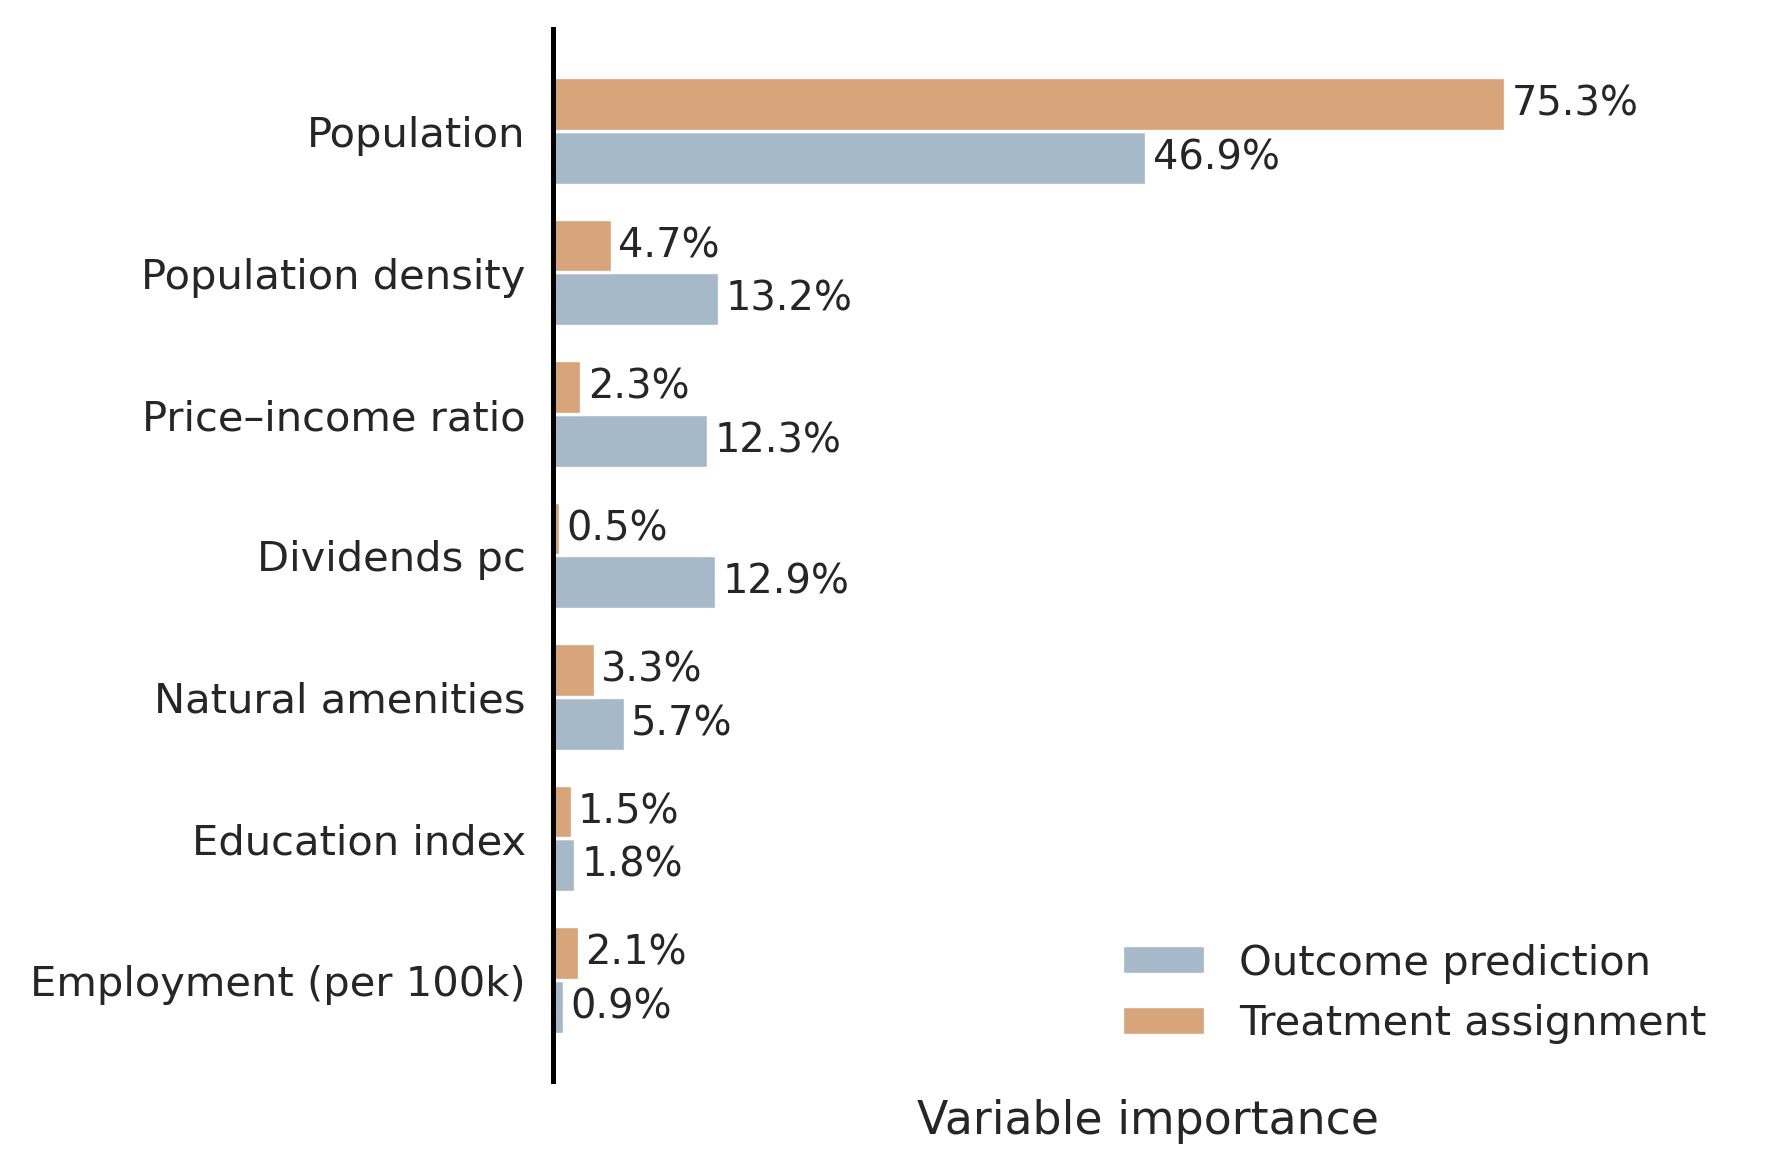

In [51]:
# Rename variables for readability
rename_map = {
    "nat_amenity_score": "Natural amenities",
    "income_price_ratio2023": "Price–income ratio",
    "gdp_pc": "GDP pc",
    "income_index_adj": "Income index",
    "real_estate_taxes_med": "Property taxes",
    "est_100k": "Number of companies",
    "POPULATION": "Population",
    "health_index_adj": "Health index",
    "personal_income_pc": "Personal income pc",
    "inequality_ratio": "Inequality ratio",
    "education_index": "Education index",
    "n_postings_100k": "Job postings (per 100k)",
    "emp_100k": "Employment (per 100k)",
    "poverty_rate_all": "Poverty rate",
    "pop_density": "Population density",
    "dividends_pc": "Dividends pc"
}

# keep only the two nuisance models
df = variable_importance.copy()
df = df[(df["hazard"] == "RISK_SCORE") & (df["model"].isin(["Y_nuisance", "W_nuisance"]))]

# mean importance by nuisance x variable
imp = (
    df.groupby(["model", "variable"], as_index=False)["importance"]
      .mean()
)

# top-7 variables by overall mean across nuisances
top_vars = (
    imp.groupby("variable")["importance"]
       .mean()
       .sort_values(ascending=False)
       .head(7)
       .index
)

imp_top = imp[imp["variable"].isin(top_vars)].copy()

# nice names + pivot wide for plotting
imp_top["variable_name"] = imp_top["variable"].map(lambda v: rename_map.get(v, v))

wide = (
    imp_top.pivot_table(index="variable_name", columns="model", values="importance", aggfunc="mean")
           .fillna(0.0)
)

# ensure consistent column order
for col in ["Y_nuisance", "W_nuisance"]:
    if col not in wide.columns:
        wide[col] = 0.0
wide = wide[["Y_nuisance", "W_nuisance"]]

# order: smallest at top for barh
wide["overall"] = wide.mean(axis=1)
wide = wide.sort_values("overall", ascending=True).drop(columns="overall")

# ---- Plot: grouped horizontal bars ----
fig, ax = plt.subplots(figsize=(6, 4))

y = np.arange(len(wide.index))
h = 0.38

vals_y = wide["Y_nuisance"].values * 100
vals_w = wide["W_nuisance"].values * 100

ax.barh(y - h/2, vals_y, height=h, label="Outcome prediction", color="#A5B9C8")
ax.barh(y + h/2, vals_w, height=h, label="Treatment assignment", color="#D8A57A")

# labels on bars
for i, v in enumerate(vals_y):
    ax.text(v + 0.5, y[i] - h/2, f"{v:.1f}%", va="center")
for i, v in enumerate(vals_w):
    ax.text(v + 0.5, y[i] + h/2, f"{v:.1f}%", va="center")

ax.set_yticks(y)
ax.set_yticklabels(wide.index)
ax.set_xlabel("Variable importance")

xmax = max(vals_y.max(), vals_w.max())
ax.set_xlim(0, xmax * 1.25)

ax.legend(frameon=False, loc="lower right")
ax.set_xticks([])

sns.despine(left=False, bottom=True)

plt.tight_layout()
plt.show()


### RISK_SCORE: moderator subgroup splits (p25/p75)

In [52]:
subgroups=pd.read_csv('../data_generated/cf_results/county/cf_subgroups.csv')
subgroups=subgroups[subgroups['hazard']=='RISK_SCORE']


In [53]:
# ---- Rename variables for readability ----
rename_map = {
    "Natural Amenities": "Natural amenities",
    "Population Density": "Population density",
    "Price-Income": "Price–income ratio",
    "GDP per Capita": "GDP pc",
    "Education Index": "Education index",
    "Number of Employed": "Employment (per 100k)",
}

subgroups["moderator"] = subgroups["moderator"].map(lambda v: rename_map.get(v, v))


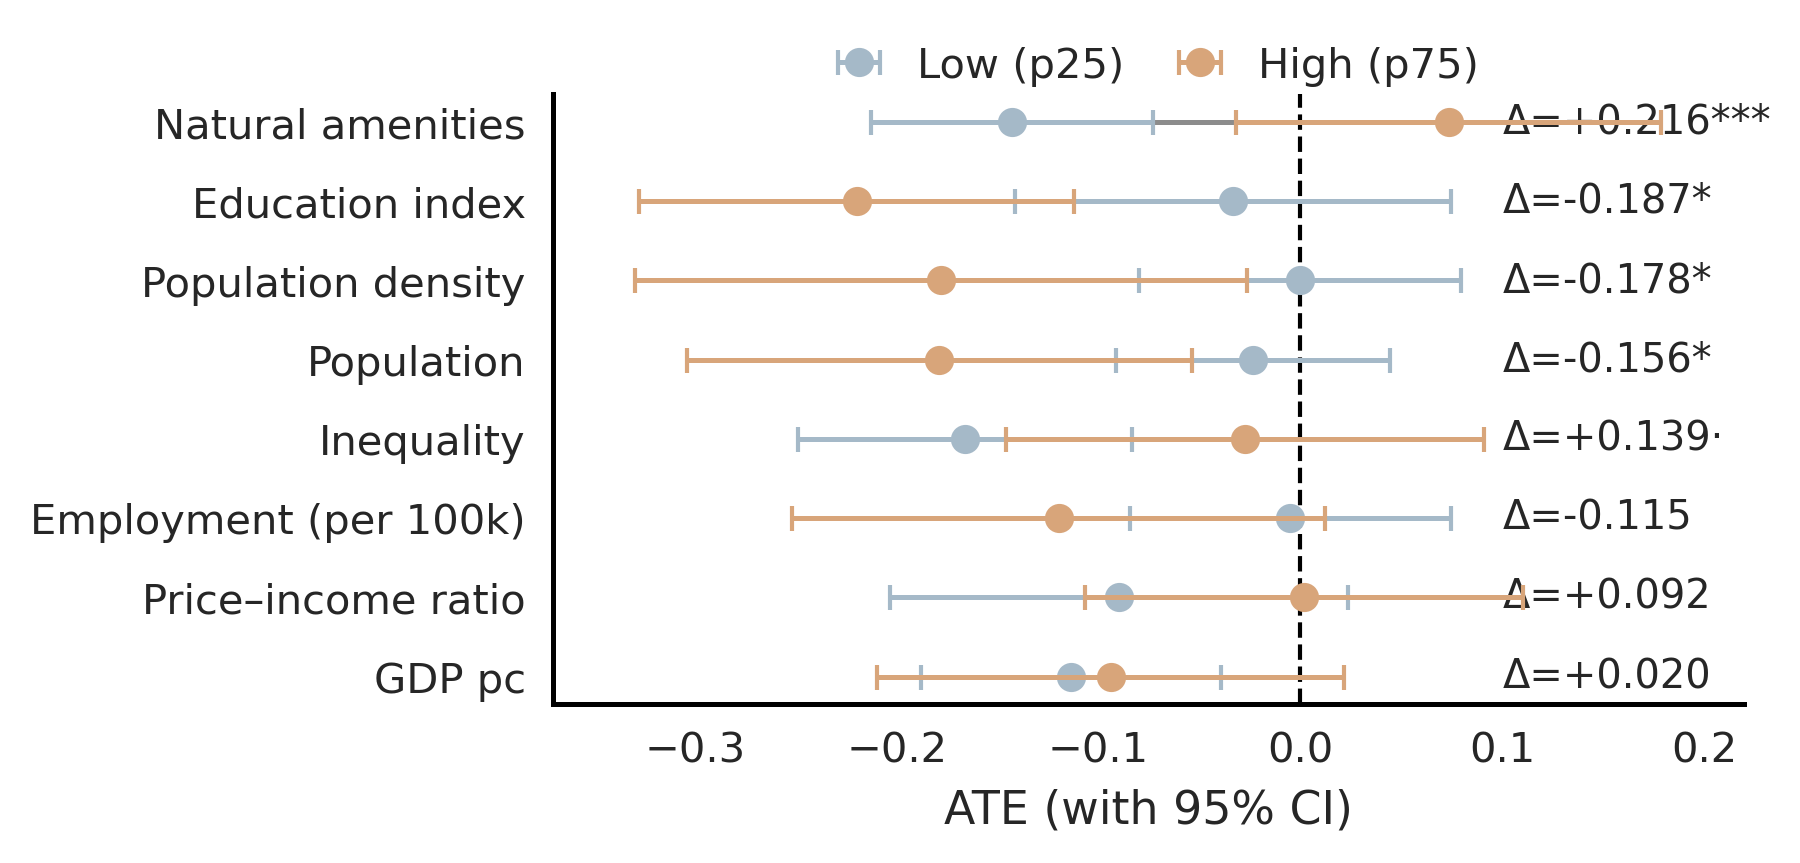

In [54]:
# ---- filter to 25/75 splits for the hazard of interest ----
df = subgroups.copy()
df = df[(df["hazard"] == "RISK_SCORE") & (df["split_type"] == "p25/p75")].copy()

# order by absolute diff
df["abs_diff"] = df["diff_est"].abs()
df = df.sort_values("abs_diff", ascending=True)

# labels
y_labels = df["moderator"].astype(str).tolist()
y = np.arange(len(df))

# values + 95% CI
low = df["ATE_low_est"].to_numpy()
high = df["ATE_high_est"].to_numpy()

low_se = df["ATE_low_se"].to_numpy()
high_se = df["ATE_high_se"].to_numpy()

low_ci = 1.96 * low_se
high_ci = 1.96 * high_se

def stars(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    if p < 0.1:
        return "·"
    return ""

df["diff_star"] = df["diff_p"].apply(stars)

# ---- plot ----
fig, ax = plt.subplots(figsize=(6, 3))

c_low = "#A5B9C8"
c_high = "#D8A57A"

for i in range(len(df)):
    ax.plot([low[i], high[i]], [y[i], y[i]], linewidth=1.2, zorder=1)

ax.errorbar(low, y, xerr=low_ci, fmt="o", markersize=6, capsize=3,
            linewidth=1.2, color=c_low, label="Low (p25)", zorder=3)

ax.errorbar(high, y, xerr=high_ci, fmt="o", markersize=6, capsize=3,
            linewidth=1.2, color=c_high, label="High (p75)", zorder=4)

ax.axvline(0, color="black", linewidth=1, linestyle="--")

ax.set_yticks(y)
ax.set_yticklabels(y_labels)

ax.set_xlabel("ATE (with 95% CI)")

xmin = np.min(np.r_[low - low_ci, high - high_ci])
xmax = np.max(np.r_[low + low_ci, high + high_ci])
pad = 0.08 * (xmax - xmin) if xmax > xmin else 0.1
ax.set_xlim(xmin - pad, xmax + pad)

x_annot = 0.1
for i in range(len(df)):
    d = df.iloc[i]["diff_est"]
    p = df.iloc[i]["diff_p"]
    s = df.iloc[i]["diff_star"]
    ax.text(x_annot, y[i], f"Δ={d:+.3f}{s}", va="center", ha="left")

ax.legend(
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.12),
    ncol=2,
    columnspacing=0.8,
    handletextpad=0.4,
    borderaxespad=0.2
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)

plt.tight_layout()
plt.show()


### Caterpillar plots: ATE / ATT / ATC / ATO across all hazards (binary treatment)

In [55]:
df=pd.read_csv('../data_generated/cf_results/county/cf_summary.csv')
df["hazard"] = df["hazard"].map(NRI_HAZARD_NAMES)


In [56]:
def caterpillar_plot(
    df,
    estimand,
    ax=None,
    title=None
):
    d = (
        df
        .sort_values(estimand)
        .reset_index(drop=True)
    )

    x = np.arange(len(d))

    if ax is None:
        fig, ax = plt.subplots(figsize=(0.45 * len(d), 5))

    ax.errorbar(
        x,
        d[estimand],
        yerr=1.96 * d["ATE_se"],
        fmt="o",
        color="black",
        ecolor="black",
        elinewidth=1,
        capsize=3
    )

    ax.axhline(0, color="grey", lw=1, linestyle="--")

    ax.set_xticks(x)
    ax.set_xticklabels(d["hazard"], rotation=45, ha="right")

    if title is None:
        title = estimand
    ax.set_title("")
    ax.set_ylabel(title)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)

    return ax


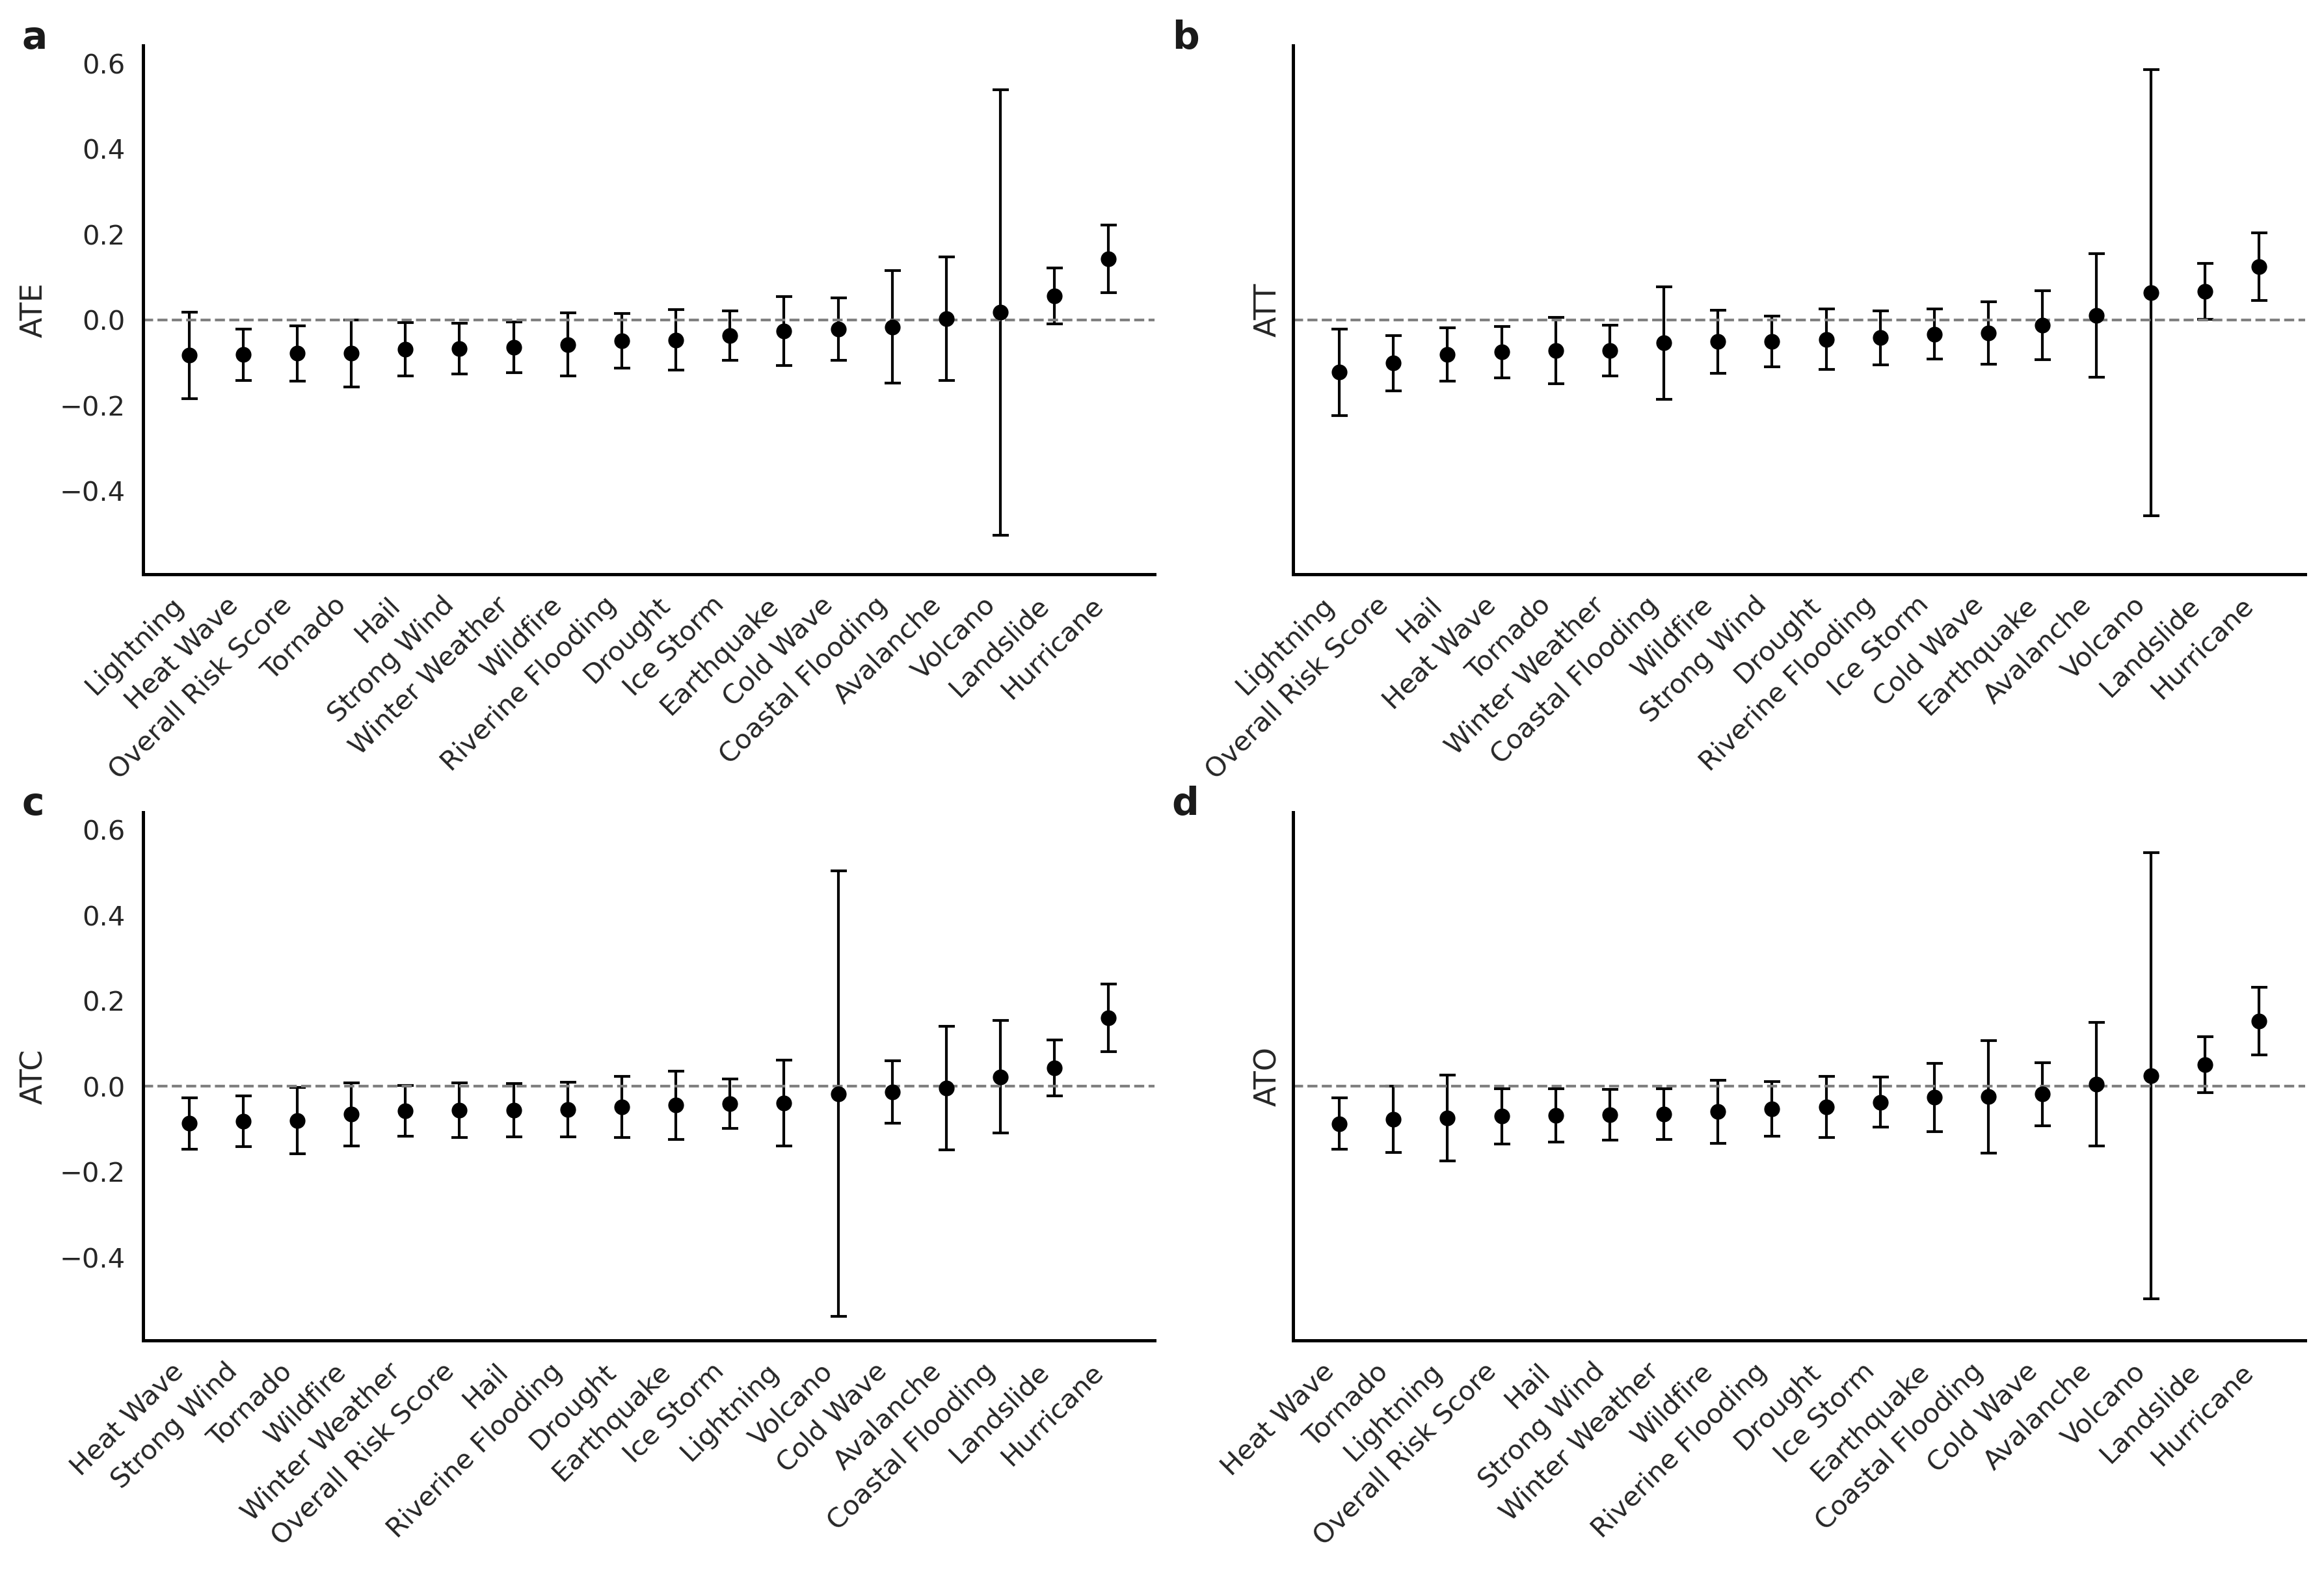

In [57]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    sharey=True
)

estimands = ["ATE", "ATT", "ATC", "ATO"]

for ax, est in zip(axes.flat, estimands):
    caterpillar_plot(
        df,
        estimand=f"{est}_est",
        ax=ax,
        title=est
    )

plt.tight_layout()

plots_l = ['a', 'b', 'c', 'd']
for ia, ax in enumerate(fig.axes):
    x,y = -0.12,0.98
    ax.text(x,y,  plots_l[ia],
        color = 'k',
        horizontalalignment='left',
        verticalalignment='bottom',
        weight = 'bold',
        transform=ax.transAxes,fontsize = 14)

plt.savefig(
    '../fig/si/si_disasters_ate_county.pdf',
    bbox_inches='tight',
    dpi=300
)

plt.show()


### Continuous treatment: RISK_SCORE CATE distribution and caterpillar plots

In [58]:
cates_all=pd.read_csv('../data_generated/cf_results/county/cf_continuous_cates.csv')
cates_all=cates_all[cates_all['hazard']=='RISK_SCORE']
results_all=pd.read_csv('../data_generated/cf_results/county/cf_continuous_summary.csv')


In [59]:
vmax = cates_all["cate"].abs().quantile(0.95)
vmin = -vmax

norm = TwoSlopeNorm(
    vmin=vmin,
    vcenter=0.0,
    vmax=vmax
)


/tmp/ipykernel_30149/3975053634.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = mpl.cm.get_cmap("RdYlBu_r")


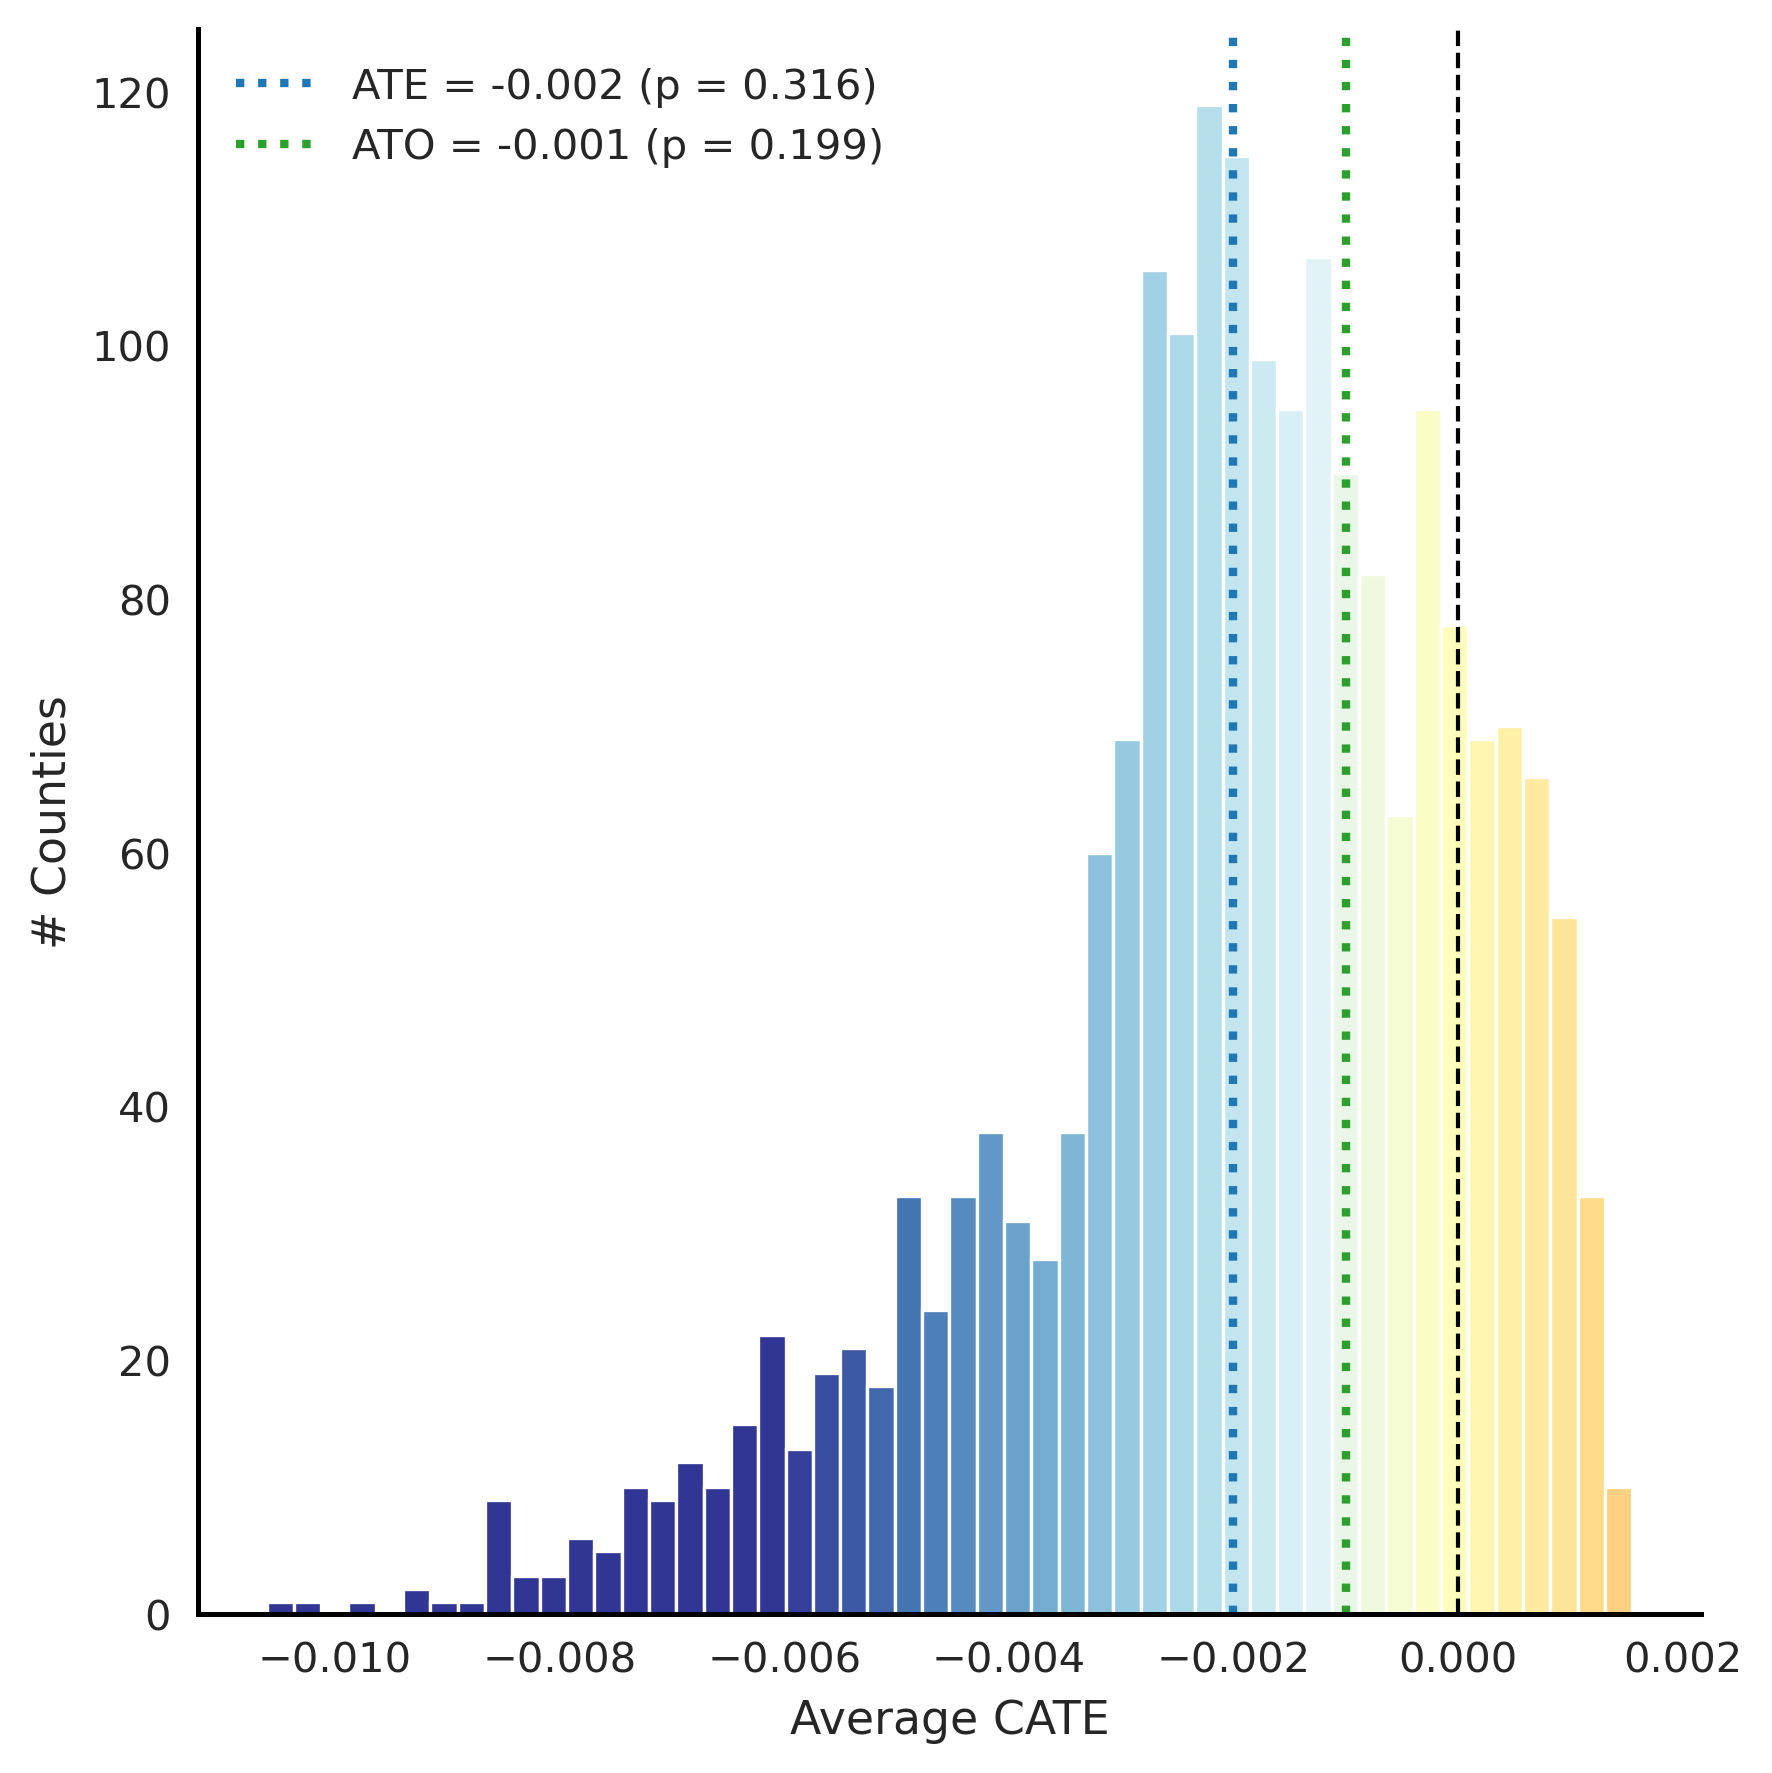

In [60]:
fig, ax = plt.subplots(figsize=(6, 6))

vals = cates_all["cate"].values

counts, bin_edges = np.histogram(vals, bins=50)

bin_mids = 0.5 * (bin_edges[:-1] + bin_edges[1:])

cmap = mpl.cm.get_cmap("RdYlBu_r")
colors = cmap(norm(bin_mids))

for left, height, width, color in zip(bin_edges[:-1], counts,
                                      np.diff(bin_edges), colors):
    ax.bar(left, height, width=width,
           color=color, edgecolor="white")

ax.axvline(0, color="black", linewidth=1, linestyle="--")

ate=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATE_est'].iloc[0], 3)
p_val=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATE_p'].iloc[0], 3)
ax.axvline(ate, lw=2, linestyle=":",
           label=f"ATE = {ate:.3f} (p = {p_val:.3f})",
           color="tab:blue")

ato=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATO_est'].iloc[0], 3)
p_val=round(results_all.loc[results_all['hazard'] == 'RISK_SCORE', 'ATO_p'].iloc[0], 3)
ax.axvline(ato, lw=2, linestyle=":",
           label=f"ATO = {ato:.3f} (p = {p_val:.3f})",
           color="tab:green")

ax.set_xlabel("Average CATE")
ax.set_ylabel("# Counties")
ax.set_title("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()

plt.show()


In [61]:
results_all["hazard"] = results_all["hazard"].map(NRI_HAZARD_NAMES)


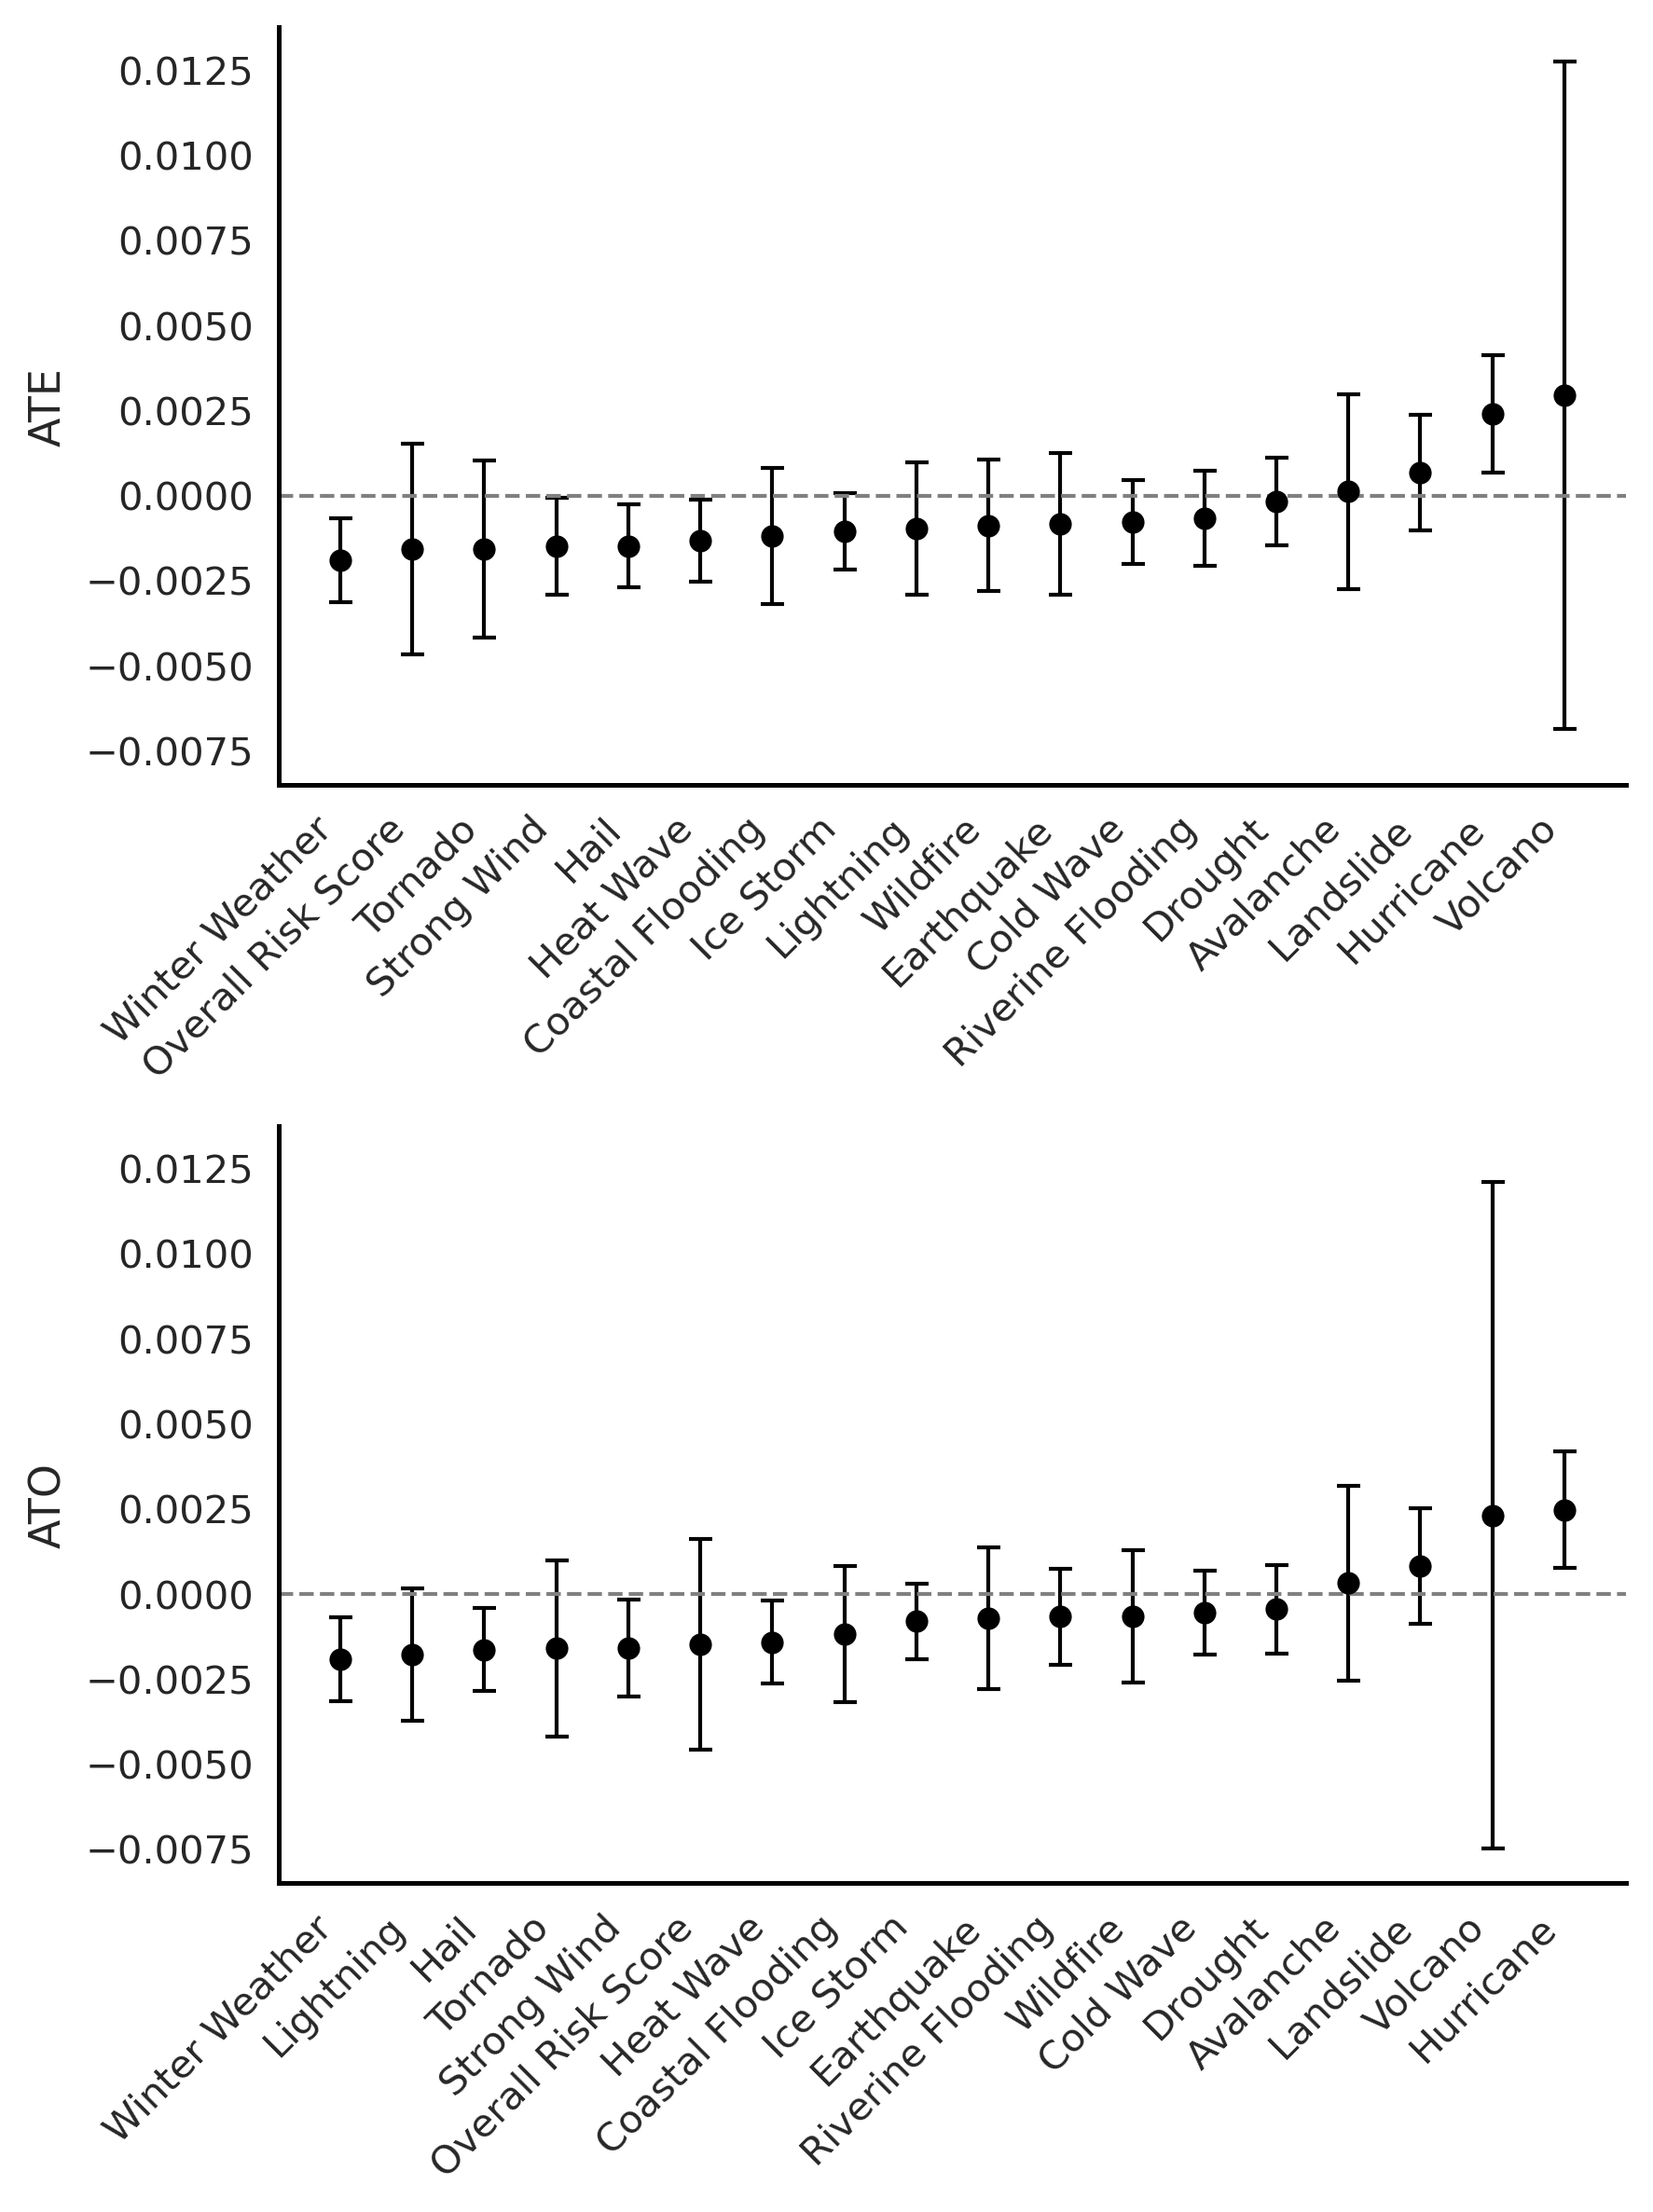

In [62]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(6, 8),
    sharey=True
)

estimands = ["ATE", "ATO"]

for ax, est in zip(axes.flat, estimands):
    caterpillar_plot(
        results_all,
        estimand=f"{est}_est",
        ax=ax,
        title=est
    )

plt.tight_layout()

plt.savefig(
    '../fig/si/si_disasters_continuous_ate_county.pdf',
    bbox_inches='tight',
    dpi=300
)

plt.show()


### RISK_SCORE placebo permutation test

In [63]:
placebo_summary=pd.read_csv('../data_generated/cf_results/county/cf_placebo_summary.csv')
placebo_perm=pd.read_csv('../data_generated/cf_results/county/cf_summary_random.csv')
placebo_summary


,hazard,n_perm,perm_mean,perm_sd,perm_p025,perm_p975,real_ate,real_se,p_perm
0,RISK_SCORE,200,-0.001761,0.018401,-0.03722,0.03436,-0.077569,0.03269,0


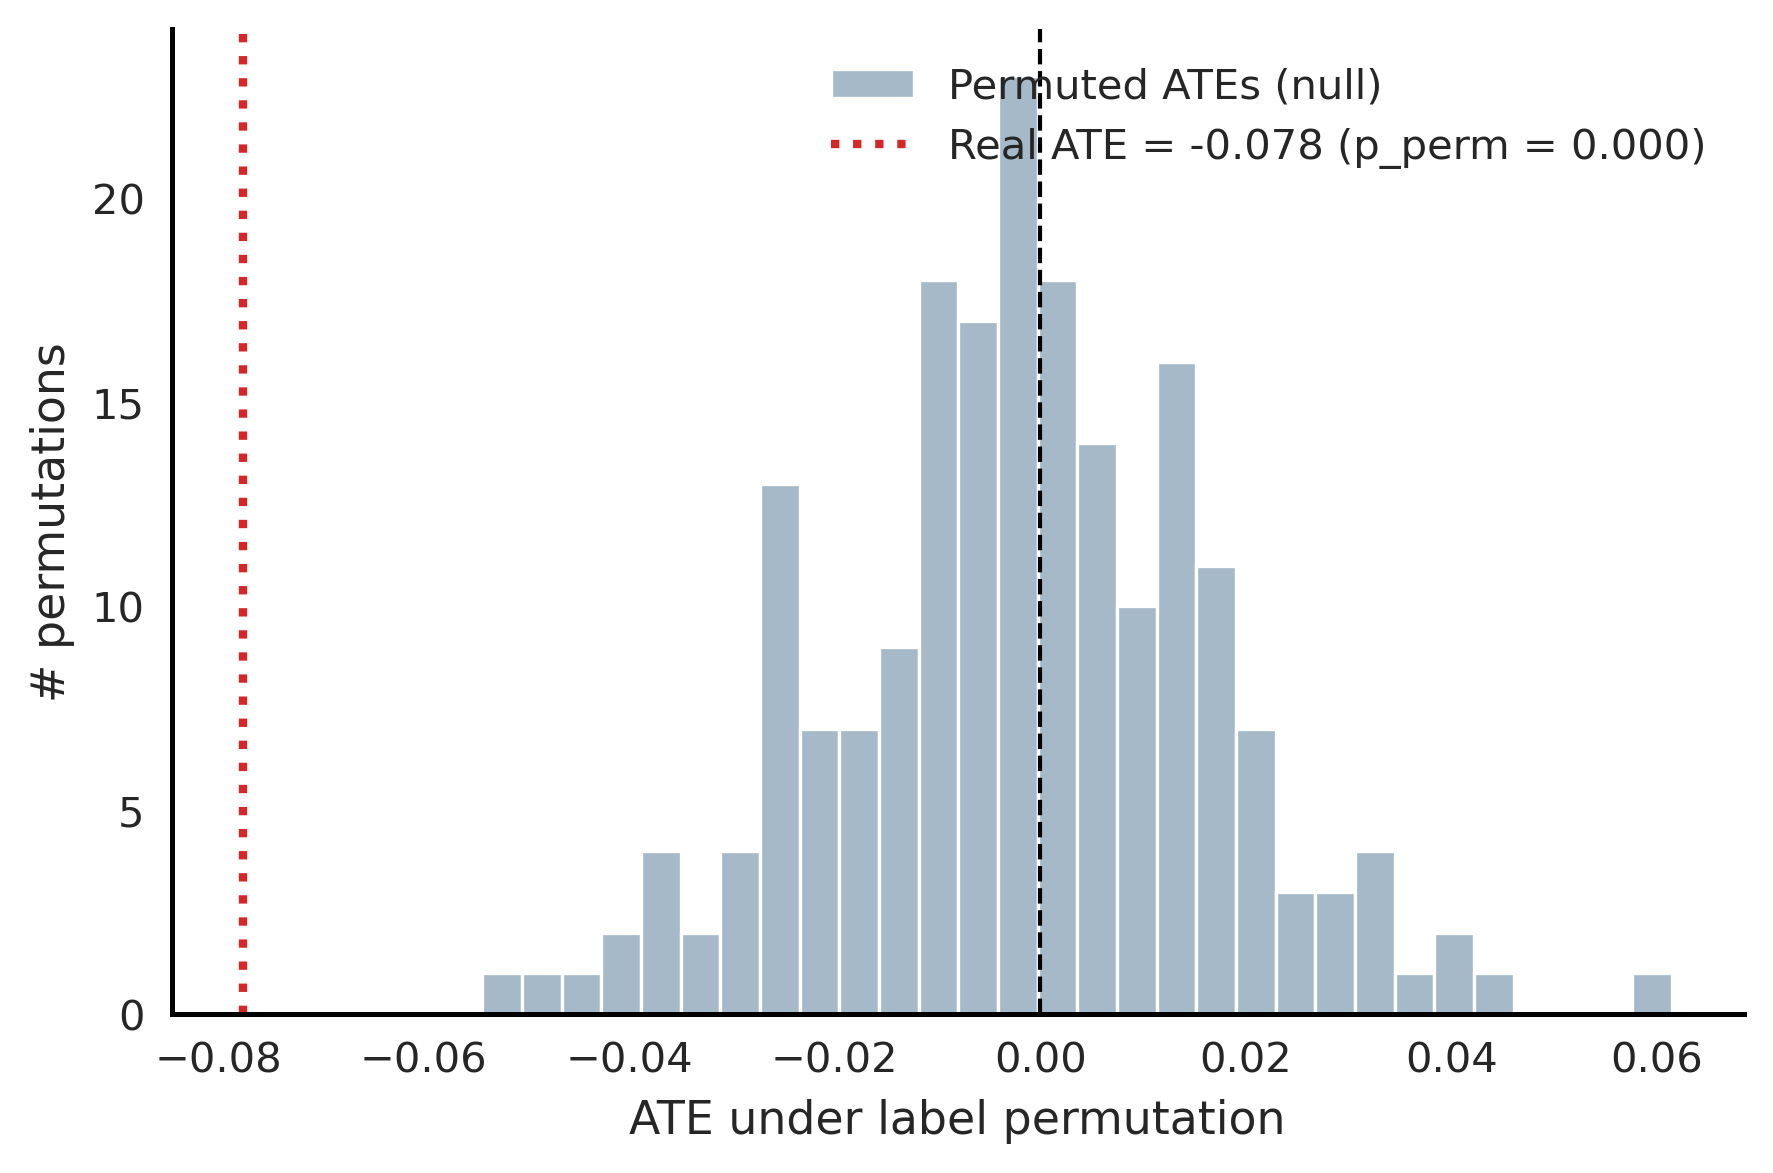

In [64]:
row = placebo_summary.loc[placebo_summary["hazard"] == "RISK_SCORE"].iloc[0]
perm_vals = placebo_perm.loc[placebo_perm["hazard"] == "RISK_SCORE", "perm_ate"].dropna()

fig, ax = plt.subplots(figsize=(6, 4))

ax.hist(perm_vals, bins=30, color="#A5B9C8", edgecolor="white", label="Permuted ATEs (null)")
ax.axvline(row["real_ate"], color="tab:red", lw=2, linestyle=":",
           label=f"Real ATE = {row['real_ate']:.3f} (p_perm = {row['p_perm']:.3f})")
ax.axvline(0, color="black", lw=1, linestyle="--")

ax.set_xlabel("ATE under label permutation")
ax.set_ylabel("# permutations")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()
